<a href="https://colab.research.google.com/github/malikshahzaib263/cardboard-measurement-cv/blob/main/cardboard_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip -q install opencv-python-headless matplotlib pillow numpy


In [ ]:

import os
import zipfile
import glob
from google.colab import files

uploaded = files.upload()
zip_name = next(iter(uploaded))

os.makedirs("/content/cardboard_dataset", exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("/content/cardboard_dataset")

image_paths = []
for ext in ["jpg", "jpeg", "png", "JPG", "JPEG", "PNG"]:
    image_paths += glob.glob(
        f"/content/cardboard_dataset/**/*.{ext}",
        recursive=True
    )

image_paths = sorted(set(image_paths))

print("Total images:", len(image_paths))


Saving cardboard_dataset_final_78_photos.zip to cardboard_dataset_final_78_photos.zip
Total images: 78


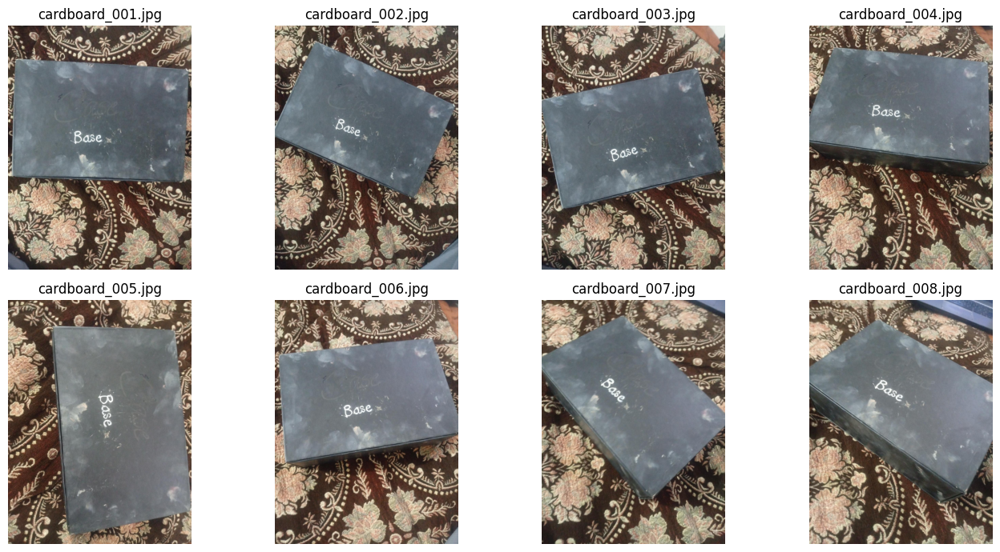

In [ ]:

import cv2
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, path in zip(axes.flat, image_paths[:8]):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(os.path.basename(path))
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

!pip -q install segment-anything
!wget -q -O sam_vit_b.pth \
https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth


In [ ]:

import torch
from segment_anything import sam_model_registry, SamPredictor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

sam = sam_model_registry["vit_b"](
    checkpoint="sam_vit_b.pth"
)
sam.to(device=device)
sam.eval()

predictor = SamPredictor(sam)
print("SAM model loaded successfully!")


Device: cpu
SAM model loaded successfully!


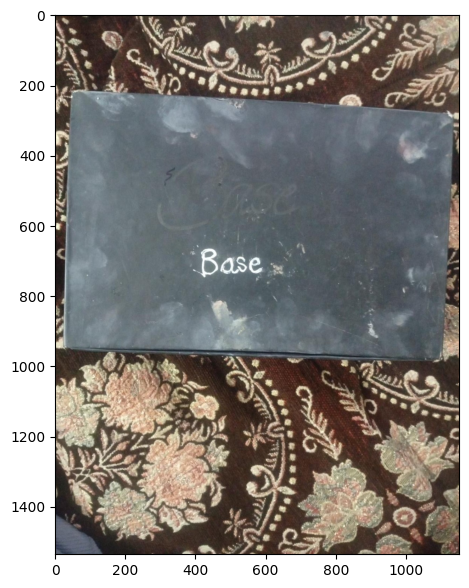

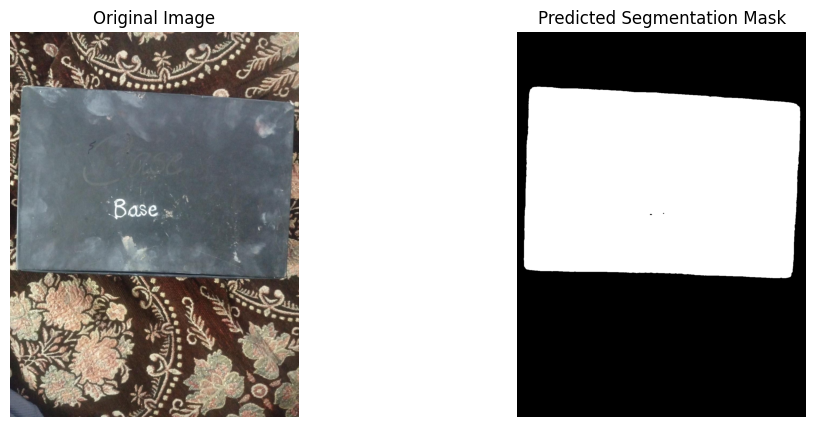

SAM confidence score: 0.9931272


In [ ]:

import numpy as np

image_path = image_paths[0]
image = cv2.cvtColor(
    cv2.imread(image_path),
    cv2.COLOR_BGR2RGB
)

predictor.set_image(image)

# Display image to identify coordinates
plt.figure(figsize=(9, 7))
plt.imshow(image)
plt.axis("on")
plt.show()

# Change these coordinates to a point inside the box
point_x = image.shape[1] // 2
point_y = image.shape[0] // 2

masks, scores, logits = predictor.predict(
    point_coords=np.array([[point_x, point_y]]),
    point_labels=np.array([1]),
    multimask_output=True
)

best_index = int(np.argmax(scores))
mask = masks[best_index]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Predicted Segmentation Mask")

for ax in axes:
    ax.axis("off")

plt.show()

print("SAM confidence score:", scores[best_index])


In [ ]:

os.makedirs("/content/segmentation_masks", exist_ok=True)

mask_filename = (
    os.path.splitext(os.path.basename(image_path))[0]
    + "_mask.png"
)

mask_path = os.path.join(
    "/content/segmentation_masks",
    mask_filename
)

cv2.imwrite(
    mask_path,
    (mask.astype(np.uint8) * 255)
)

print("Saved mask:", mask_path)


Saved mask: /content/segmentation_masks/cardboard_001_mask.png


In [ ]:

import os
import cv2
import numpy as np
import torch
from tqdm.auto import tqdm

mask_dir = "/content/segmentation_masks"
os.makedirs(mask_dir, exist_ok=True)

for path in tqdm(image_paths):
    img_bgr = cv2.imread(path)
    if img_bgr is None:
        continue

    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    predictor.set_image(img)

    h, w = img.shape[:2]

    # Initial prompt: centre of image
    point = np.array([[w // 2, h // 2]])

    masks, scores, _ = predictor.predict(
        point_coords=point,
        point_labels=np.array([1]),
        multimask_output=True
    )

    best = int(np.argmax(scores))
    mask = masks[best].astype(np.uint8) * 255

    filename = os.path.splitext(
        os.path.basename(path)
    )[0] + "_mask.png"

    cv2.imwrite(os.path.join(mask_dir, filename), mask)

print("Batch prediction finished!")
print("Saved masks:", len(os.listdir(mask_dir)))


  0%|          | 0/78 [00:00<?, ?it/s]

Batch prediction finished!
Saved masks: 78


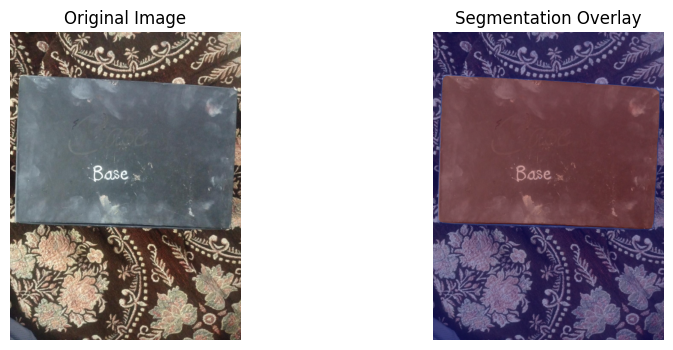

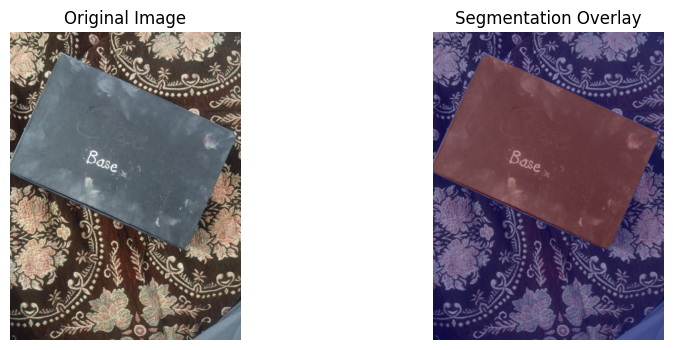

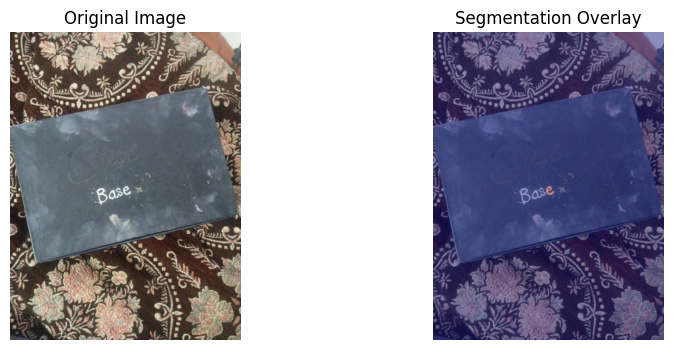

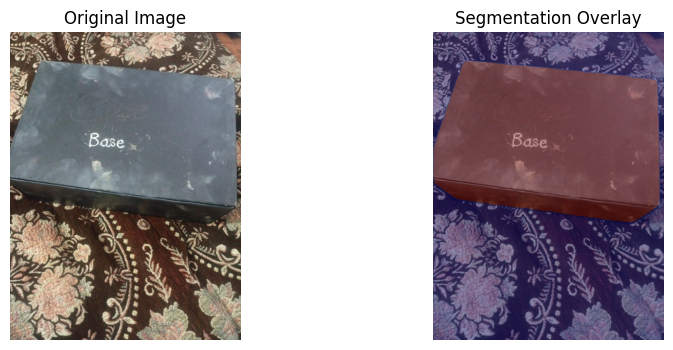

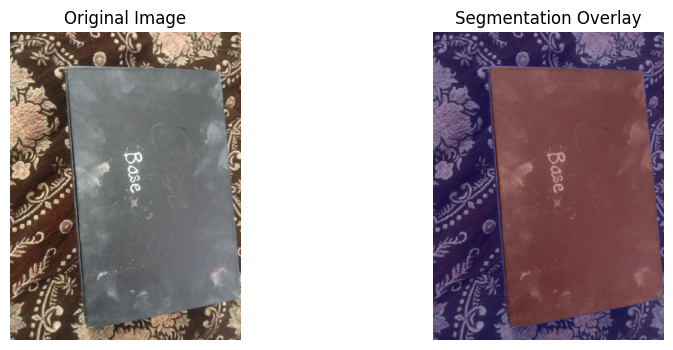

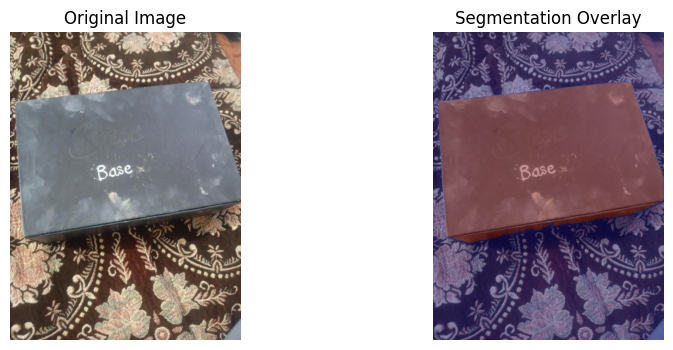

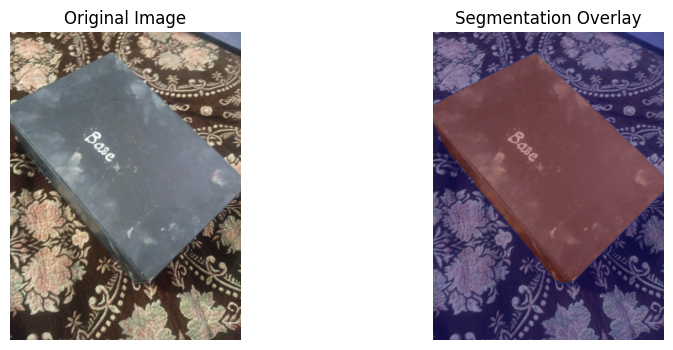

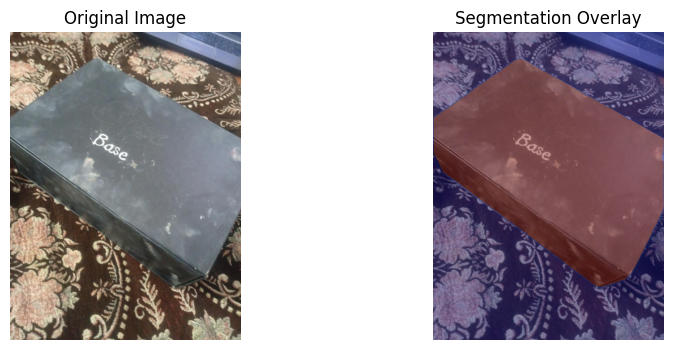

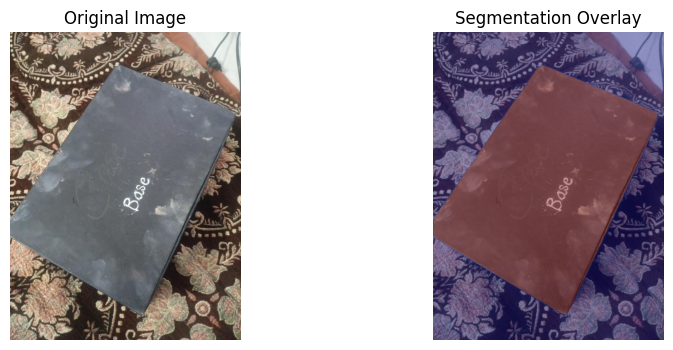

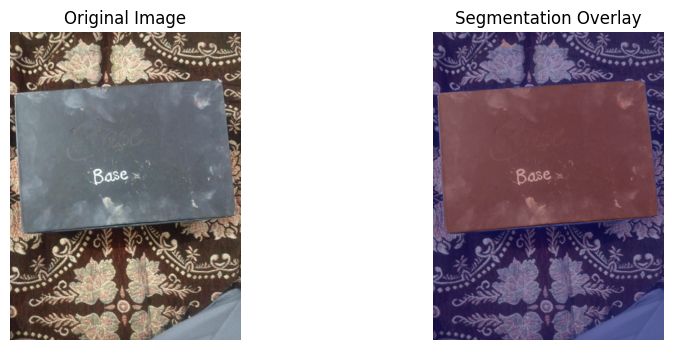

In [ ]:

import matplotlib.pyplot as plt

for path in image_paths[:10]:
    filename = os.path.splitext(
        os.path.basename(path)
    )[0] + "_mask.png"

    mask_path = os.path.join(mask_dir, filename)

    img = cv2.cvtColor(
        cv2.imread(path), cv2.COLOR_BGR2RGB
    )
    mask = cv2.imread(mask_path, 0)

    if mask is None:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(img)
    axes[0].set_title("Original Image")

    axes[1].imshow(img)
    axes[1].imshow(mask, cmap="jet", alpha=0.4)
    axes[1].set_title("Segmentation Overlay")

    for ax in axes:
        ax.axis("off")

    plt.show()


In [ ]:

import os
import cv2
import numpy as np

X = []
Y = []
valid_names = []

for path in image_paths:
    name = os.path.splitext(os.path.basename(path))[0]
    mask_path = os.path.join(mask_dir, name + "_mask.png")

    img = cv2.imread(path)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if img is None or mask is None:
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img = cv2.resize(img, (256, 256))
    mask = cv2.resize(
        mask, (256, 256),
        interpolation=cv2.INTER_NEAREST
    )

    X.append(img.astype(np.float32) / 255.0)
    Y.append((mask > 127).astype(np.float32)[..., None])
    valid_names.append(name)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)

print("Images:", X.shape)
print("Masks:", Y.shape)


Images: (78, 256, 256, 3)
Masks: (78, 256, 256, 1)


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_temp, Y_train, Y_temp = train_test_split(
    X, Y, test_size=0.30, random_state=42
)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, Y_temp,
    test_size=1/3,
    random_state=42
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))


Training: 54
Validation: 16
Testing: 8


In [ ]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

review_items = []

for path in image_paths:
    name = os.path.splitext(os.path.basename(path))[0]
    mask_path = os.path.join(mask_dir, name + "_mask.png")

    if os.path.exists(mask_path):
        review_items.append((path, mask_path))

review_results = {}
current_index = 0

output = widgets.Output()
status = widgets.HTML()

correct_btn = widgets.Button(
    description="Correct",
    button_style="success"
)

incorrect_btn = widgets.Button(
    description="Incorrect",
    button_style="danger"
)

previous_btn = widgets.Button(
    description="Previous"
)

def show_image():
    global current_index

    with output:
        clear_output(wait=True)

        if current_index >= len(review_items):
            print("Review completed!")
            return

        img_path, mask_path = review_items[current_index]

        img = cv2.cvtColor(
            cv2.imread(img_path),
            cv2.COLOR_BGR2RGB
        )
        mask = cv2.imread(mask_path, 0)

        contours, _ = cv2.findContours(
            (mask > 127).astype(np.uint8),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        overlay = img.copy()

        cv2.drawContours(
            overlay, contours, -1, (255, 0, 0), 3
        )

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        axes[0].imshow(img)
        axes[0].set_title("Original")

        axes[1].imshow(overlay)
        axes[1].set_title("Red = Predicted Mask Boundary")

        for ax in axes:
            ax.axis("off")

        plt.show()

    status.value = (
        f"<b>Image {current_index + 1} "
        f"of {len(review_items)}</b>"
    )

def save_review(result):
    global current_index

    if current_index >= len(review_items):
        return

    name = os.path.basename(review_items[current_index][0])
    review_results[name] = result

    current_index += 1
    show_image()

def mark_correct(btn):
    save_review("correct")

def mark_incorrect(btn):
    save_review("incorrect")

def go_previous(btn):
    global current_index
    current_index = max(0, current_index - 1)
    show_image()

correct_btn.on_click(mark_correct)
incorrect_btn.on_click(mark_incorrect)
previous_btn.on_click(go_previous)

display(status)
display(widgets.HBox([
    previous_btn, correct_btn, incorrect_btn
]))
display(output)

show_image()


HTML(value='')

Output()

In [ ]:

print("Total images:", len(image_paths))
print("Masks available:", len(review_items))
print("Reviewed images:", len(review_results))
print("Current image:", current_index)



Total images: 78
Masks available: 78
Reviewed images: 0
Current image: 0


In [ ]:

print("Reviewed:", len(review_results))
print(review_results)


Reviewed: 0
{}


In [ ]:

import os
import cv2
import csv
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# Existing notebook variables:
# image_paths = list of cardboard image paths
# mask_dir = "/content/segmentation_masks"

report_path = "/content/mask_review_report.csv"

review_items = []

for path in image_paths:
    name = os.path.splitext(os.path.basename(path))[0]
    mask_path = os.path.join(mask_dir, name + "_mask.png")

    if os.path.isfile(mask_path):
        review_items.append((path, mask_path))

review_items.sort()

# Restore saved reviews if available
review_results = {}

if os.path.exists(report_path):
    with open(report_path, newline="") as f:
        reader = csv.DictReader(f)
        for row in reader:
            if row.get("status") in ("correct", "incorrect"):
                review_results[row["filename"]] = row["status"]

current_index = 0

status = widgets.HTML()
output = widgets.Output()

correct_btn = widgets.Button(
    description="Correct",
    button_style="success",
    icon="check"
)

incorrect_btn = widgets.Button(
    description="Incorrect",
    button_style="danger",
    icon="times"
)

previous_btn = widgets.Button(
    description="Previous",
    icon="arrow-left"
)

next_btn = widgets.Button(
    description="Next",
    icon="arrow-right"
)

def save_report():
    with open(report_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["filename", "status"])

        for filename, result in review_results.items():
            writer.writerow([filename, result])

def show_image():
    global current_index

    with output:
        clear_output(wait=True)

        if not review_items:
            print("No masks found. Run mask generation first.")
            return

        current_index = max(
            0, min(current_index, len(review_items) - 1)
        )

        img_path, mask_path = review_items[current_index]

        img = cv2.imread(img_path)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        if img is None or mask is None:
            print("Could not read:", img_path)
            return

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if mask.shape != img.shape[:2]:
            mask = cv2.resize(
                mask, (img.shape[1], img.shape[0]),
                interpolation=cv2.INTER_NEAREST
            )

        binary_mask = (mask > 127).astype(np.uint8)

        contours, _ = cv2.findContours(
            binary_mask,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        overlay = img.copy()

        cv2.drawContours(
            overlay, contours, -1, (255, 0, 0), 3
        )

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        axes[0].imshow(img)
        axes[0].set_title("Original Image")

        axes[1].imshow(overlay)
        axes[1].set_title("Segmentation Boundary (Red)")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()
        plt.show()
        plt.close(fig)

    filename = os.path.basename(review_items[current_index][0])
    reviewed = len([
        name for name, _ in review_items
        if os.path.basename(name) in review_results
    ])

    status.value = (
        f"<b>Image {current_index + 1}/{len(review_items)}</b>"
        f" | Reviewed: {reviewed}"
        f" | Current status: "
        f"{review_results.get(filename, 'Not reviewed')}"
    )

def mark_review(result):
    global current_index

    if not review_items:
        return

    filename = os.path.basename(review_items[current_index][0])

    review_results[filename] = result
    save_report()

    if current_index < len(review_items) - 1:
        current_index += 1

    show_image()

def mark_correct(btn):
    mark_review("correct")

def mark_incorrect(btn):
    mark_review("incorrect")

def go_previous(btn):
    global current_index
    current_index -= 1
    show_image()

def go_next(btn):
    global current_index
    current_index += 1
    show_image()

correct_btn.on_click(mark_correct)
incorrect_btn.on_click(mark_incorrect)
previous_btn.on_click(go_previous)
next_btn.on_click(go_next)

display(status)
display(widgets.HBox([
    previous_btn,
    correct_btn,
    incorrect_btn,
    next_btn
]))
display(output)

show_image()


HTML(value='')

Output()

In [ ]:

import pandas as pd
from google.colab import files

report = pd.DataFrame(
    [
        {"filename": name, "status": result}
        for name, result in review_results.items()
    ],
    columns=["filename", "status"]
)

print("Total images:", len(review_items))
print("Reviewed:", len(report))
print("Correct:", (report["status"] == "correct").sum())
print("Incorrect:", (report["status"] == "incorrect").sum())
print("Remaining:", len(review_items) - len(report))

display(report)

if not report.empty:
    report.to_csv(report_path, index=False)
    files.download(report_path)


Total images: 78
Reviewed: 78
Correct: 76
Incorrect: 2
Remaining: 0


,filename,status
0,cardboard_001.jpg,correct
1,cardboard_002.jpg,correct
2,cardboard_003.jpg,correct
3,cardboard_004.jpg,incorrect
4,cardboard_005.jpg,correct
...,...,...
73,cardboard_074.jpg,correct
74,cardboard_075.jpg,correct
75,cardboard_076.jpg,correct
76,cardboard_077.jpg,correct


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
import os

report = pd.read_csv("/content/mask_review_report.csv")

incorrect = report[report["status"] == "incorrect"]

print("Incorrect masks:", len(incorrect))
print(incorrect["filename"].to_list())

display(incorrect)


Incorrect masks: 2
['cardboard_004.jpg', 'cardboard_078.jpg']


,filename,status
3,cardboard_004.jpg,incorrect
77,cardboard_078.jpg,incorrect


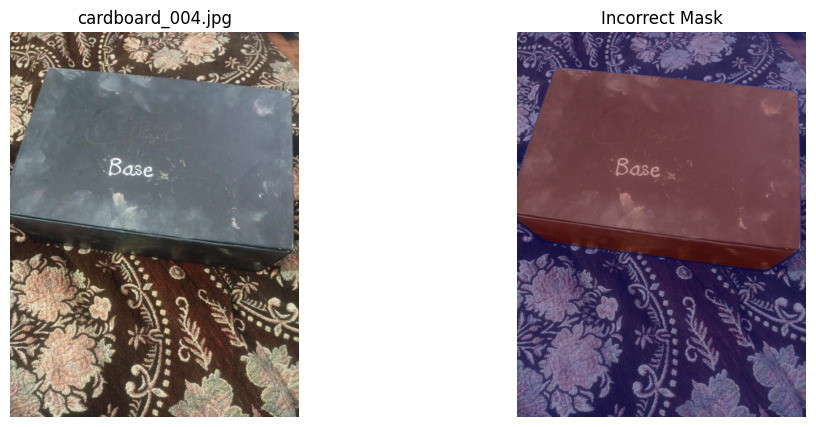

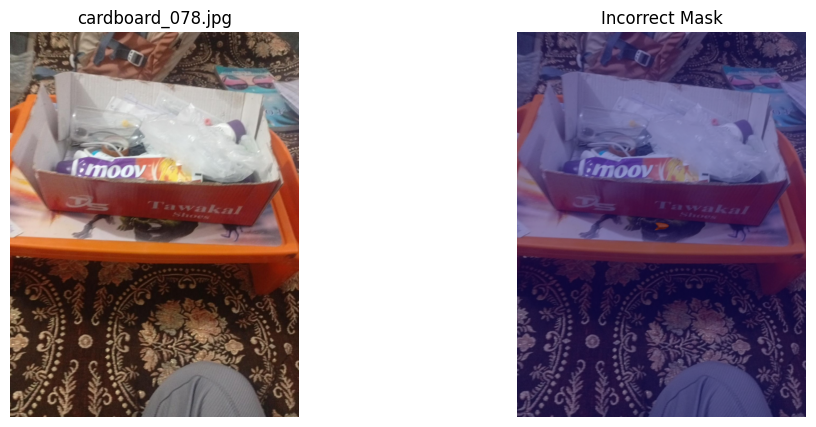

In [ ]:

import cv2
import matplotlib.pyplot as plt

for filename in incorrect["filename"]:
    matching = [
        p for p in image_paths
        if os.path.basename(p) == filename
    ]

    if not matching:
        print("Image not found:", filename)
        continue

    path = matching[0]
    name = os.path.splitext(filename)[0]
    mask_path = os.path.join(mask_dir, name + "_mask.png")

    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(mask_path, 0)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(img)
    axes[0].set_title(filename)

    axes[1].imshow(img)
    axes[1].imshow(mask, alpha=0.4, cmap="jet")
    axes[1].set_title("Incorrect Mask")

    for ax in axes:
        ax.axis("off")

    plt.show()


In [ ]:
import torch
print("GPU available:", torch.cuda.is_available())
print("Device:", device)

GPU available: False
Device: cpu


In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPU mode")

GPU available: False
CPU mode


In [ ]:

import cv2
import numpy as np
import torch

# CPU performance settings
torch.set_num_threads(4)

def prepare_fast_image(image, max_size=512):
    h, w = image.shape[:2]
    scale = min(max_size / max(h, w), 1.0)

    new_w = max(1, int(w * scale))
    new_h = max(1, int(h * scale))

    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    return resized

print("CPU optimization ready!")


CPU optimization ready!


In [ ]:

import os
import cv2
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Load verified review report
report = pd.read_csv("/content/mask_review_report.csv")

correct_files = set(
    report.loc[
        report["status"] == "correct", "filename"
    ].tolist()
)

X, Y, names = [], [], []

for path in image_paths:
    filename = os.path.basename(path)

    if filename not in correct_files:
        continue

    mask_path = os.path.join(
        mask_dir,
        os.path.splitext(filename)[0] + "_mask.png"
    )

    img = cv2.imread(path)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if img is None or mask is None:
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img = cv2.resize(img, (256, 256))
    mask = cv2.resize(
        mask, (256, 256),
        interpolation=cv2.INTER_NEAREST
    )

    X.append(img.astype(np.float32) / 255.0)
    Y.append((mask > 127).astype(np.float32)[..., None])
    names.append(filename)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)

print("Verified images:", len(X))
print("Images shape:", X.shape)
print("Masks shape:", Y.shape)

assert len(X) == 76, "Expected 76 verified images"


Verified images: 76
Images shape: (76, 256, 256, 3)
Masks shape: (76, 256, 256, 1)


In [ ]:

indices = np.arange(len(X))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=1/3,
    random_state=42
)

X_train, Y_train = X[train_idx], Y[train_idx]
X_val, Y_val = X[val_idx], Y[val_idx]
X_test, Y_test = X[test_idx], Y[test_idx]

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("Train filenames:", [names[i] for i in train_idx])
print("Test filenames:", [names[i] for i in test_idx])


Training: 53
Validation: 15
Testing: 8
Train filenames: ['cardboard_018.jpg', 'cardboard_066.jpg', 'cardboard_056.jpg', 'cardboard_033.jpg', 'cardboard_009.jpg', 'cardboard_064.jpg', 'cardboard_046.jpg', 'cardboard_074.jpg', 'cardboard_051.jpg', 'cardboard_077.jpg', 'cardboard_021.jpg', 'cardboard_065.jpg', 'cardboard_027.jpg', 'cardboard_044.jpg', 'cardboard_015.jpg', 'cardboard_057.jpg', 'cardboard_005.jpg', 'cardboard_019.jpg', 'cardboard_040.jpg', 'cardboard_010.jpg', 'cardboard_063.jpg', 'cardboard_008.jpg', 'cardboard_038.jpg', 'cardboard_071.jpg', 'cardboard_058.jpg', 'cardboard_048.jpg', 'cardboard_076.jpg', 'cardboard_017.jpg', 'cardboard_029.jpg', 'cardboard_043.jpg', 'cardboard_028.jpg', 'cardboard_050.jpg', 'cardboard_026.jpg', 'cardboard_045.jpg', 'cardboard_070.jpg', 'cardboard_059.jpg', 'cardboard_013.jpg', 'cardboard_034.jpg', 'cardboard_075.jpg', 'cardboard_061.jpg', 'cardboard_068.jpg', 'cardboard_039.jpg', 'cardboard_031.jpg', 'cardboard_002.jpg', 'cardboard_054.jpg'

In [29]:

import torch
import tensorflow as tf

print("PyTorch CUDA:", torch.cuda.is_available())
print("TensorFlow GPUs:", tf.config.list_physical_devices("GPU"))

!nvidia-smi


PyTorch CUDA: False
TensorFlow GPUs: []
/bin/bash: line 1: nvidia-smi: command not found


In [1]:

import torch
import tensorflow as tf

print("PyTorch CUDA:", torch.cuda.is_available())
print("TensorFlow GPUs:", tf.config.list_physical_devices("GPU"))

!nvidia-smi


PyTorch CUDA: True
TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Tue Nov 17 19:13:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                    

In [2]:
import os

print("Dataset:", os.path.exists("/content/segmentation_masks"))
print("Review report:", os.path.exists("/content/mask_review_report.csv"))
print("Images loaded:", len(image_paths) if "image_paths" in globals() else "Not loaded")

Dataset: False
Review report: False
Images loaded: Not loaded


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

root = "/content/drive/MyDrive"

keywords = [
    "cardboard",
    "segmentation",
    "mask_review",
    "sam_vit"
]

matches = []

for folder, dirs, files in os.walk(root):
    for filename in files:
        if any(k in filename.lower() for k in keywords):
            matches.append(os.path.join(folder, filename))

print("Files found:", len(matches))

for path in matches[:100]:
    print(path)

Files found: 1
/content/drive/MyDrive/Colab Notebooks/cardboard_segmentation.ipynb


In [5]:
import os

root = "/content/drive/MyDrive"

extensions = (".zip", ".jpg", ".jpeg", ".png", ".npy", ".npz")

found = []

for folder, dirs, files in os.walk(root):
    for filename in files:
        if filename.lower().endswith(extensions):
            found.append(os.path.join(folder, filename))

print("Total image/ZIP files found:", len(found))

for path in found[:100]:
    print(path)

Total image/ZIP files found: 35
/content/drive/MyDrive/shahzaib arshad.jpg
/content/drive/MyDrive/shahzaib arshad paymentt ss.jpg
/content/drive/MyDrive/BidGenius-AI-Full-Frontend.zip
/content/drive/MyDrive/Meezan_Receipt_776593_2026625145458.png
/content/drive/MyDrive/IMG-20260804-WA0086.jpg
/content/drive/MyDrive/bank management system/bank-management-system-main (2).zip
/content/drive/MyDrive/FYP_STUTTER/strong_features-v4/y.npy
/content/drive/MyDrive/FYP_STUTTER/strong_features-v4/X_seq_v4.npy
/content/drive/MyDrive/FYP_STUTTER/strong_features-v4/cnn_bilstm_attention_torch/confusion_matrix.npy
/content/drive/MyDrive/FYP_STUTTER/output_strong_v4/confusion_matrix.npy
/content/drive/MyDrive/FYP_STUTTER/features_super_v3/Block_super_v3_X.npy
/content/drive/MyDrive/FYP_STUTTER/features_super_v3/Interjection_super_v3_X.npy
/content/drive/MyDrive/FYP_STUTTER/features_super_v3/NaturalPause_super_v3_X.npy
/content/drive/MyDrive/FYP_STUTTER/features_super_v3/Prolongation_super_v3_X.npy
/cont

In [6]:
import os

print("Files in /content:")
print(os.listdir("/content"))

Files in /content:
['.config', 'drive', 'sample_data']


In [7]:
import os

root = "/content/drive/MyDrive"
extensions = (".zip", ".jpg", ".jpeg", ".png")

found = []

for folder, dirs, files in os.walk(root):
    for filename in files:
        if filename.lower().endswith(extensions):
            found.append(os.path.join(folder, filename))

print("Total files found:", len(found))

for path in found[:100]:
    print(path)

Total files found: 21
/content/drive/MyDrive/shahzaib arshad.jpg
/content/drive/MyDrive/shahzaib arshad paymentt ss.jpg
/content/drive/MyDrive/BidGenius-AI-Full-Frontend.zip
/content/drive/MyDrive/Meezan_Receipt_776593_2026625145458.png
/content/drive/MyDrive/IMG-20260804-WA0086.jpg
/content/drive/MyDrive/bank management system/bank-management-system-main (2).zip
/content/drive/MyDrive/youtube/logo of youtube.png
/content/drive/MyDrive/youtube/banner of youtube.png
/content/drive/MyDrive/youtube/watermark.png
/content/drive/MyDrive/youtube/KidsHut_KH_Watermark_150x150.png
/content/drive/MyDrive/youtube/rivers/crystal river.png
/content/drive/MyDrive/youtube/characters/leo/leo character.png
/content/drive/MyDrive/youtube/characters/lily/lily.png
/content/drive/MyDrive/youtube/characters/Benny/Benny.png
/content/drive/MyDrive/youtube/characters/max/max.png
/content/drive/MyDrive/youtube/characters/Bella/Bella.png
/content/drive/MyDrive/youtube/backgrounds/rabbit family house/rabbit famil

In [8]:
from google.colab import files

uploaded = files.upload()

Saving cardboard_dataset_final_78_photos.zip to cardboard_dataset_final_78_photos.zip


In [9]:
import os
import zipfile
import glob

zip_files = glob.glob("/content/*.zip")
print("ZIP files:", zip_files)

assert len(zip_files) == 1, "Expected one ZIP file"

dataset_dir = "/content/cardboard_dataset"
os.makedirs(dataset_dir, exist_ok=True)

with zipfile.ZipFile(zip_files[0], "r") as z:
    z.extractall(dataset_dir)

image_paths = sorted(
    p for p in glob.glob(
        dataset_dir + "/**/*", recursive=True
    )
    if p.lower().endswith((".jpg", ".jpeg", ".png"))
    and os.path.basename(p).lower().startswith("cardboard_")
)

print("Total cardboard images:", len(image_paths))
print("First 5:", image_paths[:5])

ZIP files: ['/content/cardboard_dataset_final_78_photos.zip']
Total cardboard images: 78
First 5: ['/content/cardboard_dataset/images/cardboard_001.jpg', '/content/cardboard_dataset/images/cardboard_002.jpg', '/content/cardboard_dataset/images/cardboard_003.jpg', '/content/cardboard_dataset/images/cardboard_004.jpg', '/content/cardboard_dataset/images/cardboard_005.jpg']


In [10]:
import shutil

shutil.copytree(
    dataset_dir,
    "/content/drive/MyDrive/cardboard_dataset",
    dirs_exist_ok=True
)

print("Dataset backed up to Google Drive!")

Dataset backed up to Google Drive!


In [11]:
import os
import glob
import zipfile

zip_name = list(uploaded.keys())[0]
dataset_dir = "/content/cardboard_dataset"

os.makedirs(dataset_dir, exist_ok=True)

with zipfile.ZipFile("/content/" + zip_name, "r") as z:
    z.extractall(dataset_dir)

image_paths = sorted([
    p for p in glob.glob(dataset_dir + "/**/*", recursive=True)
    if os.path.isfile(p)
    and p.lower().endswith((".jpg", ".jpeg", ".png"))
    and os.path.basename(p).lower().startswith("cardboard_")
])

print("Total images:", len(image_paths))
print("First image:", image_paths[0] if image_paths else "Not found")

Total images: 78
First image: /content/cardboard_dataset/images/cardboard_001.jpg


In [12]:
from google.colab import drive
import shutil

drive.mount("/content/drive", force_remount=False)

shutil.copytree(
    dataset_dir,
    "/content/drive/MyDrive/cardboard_dataset",
    dirs_exist_ok=True
)

print("Backup completed!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backup completed!


In [13]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if device == "cuda" else "None")
print("Images:", len(image_paths))

Device: cuda
GPU: Tesla T4
Images: 78


In [14]:

!pip -q install segment-anything

import os
import torch
from segment_anything import sam_model_registry, SamPredictor

checkpoint = "/content/sam_vit_b.pth"

if not os.path.exists(checkpoint):
    !wget -q -O /content/sam_vit_b.pth \
      https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

device = "cuda" if torch.cuda.is_available() else "cpu"

sam = sam_model_registry["vit_b"](
    checkpoint=checkpoint
)
sam.to(device=device)
sam.eval()

predictor = SamPredictor(sam)

print("SAM loaded on:", device)


SAM loaded on: cuda


In [15]:

import cv2
import numpy as np
import shutil

mask_dir = "/content/segmentation_masks"
os.makedirs(mask_dir, exist_ok=True)

skip_files = {
    "cardboard_004.jpg",
    "cardboard_078.jpg"
}

processed = 0
failed = []

for path in image_paths:
    filename = os.path.basename(path)

    if filename in skip_files:
        continue

    img = cv2.imread(path)

    if img is None:
        failed.append(filename)
        continue

    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = rgb.shape[:2]

    predictor.set_image(rgb)

    point = np.array([[w // 2, h // 2]])
    labels = np.array([1])

    masks, scores, _ = predictor.predict(
        point_coords=point,
        point_labels=labels,
        multimask_output=True
    )

    best = masks[np.argmax(scores)]
    binary = (best.astype(np.uint8) * 255)

    save_path = os.path.join(
        mask_dir,
        os.path.splitext(filename)[0] + "_mask.png"
    )

    cv2.imwrite(save_path, binary)
    processed += 1

    if processed % 10 == 0:
        print("Processed:", processed)

print("Total generated:", processed)
print("Failed:", failed)

# Save masks permanently
shutil.copytree(
    mask_dir,
    "/content/drive/MyDrive/segmentation_masks",
    dirs_exist_ok=True
)

print("Masks backed up to Google Drive!")


Processed: 10
Processed: 20
Processed: 30
Processed: 40
Processed: 50
Processed: 60
Processed: 70
Total generated: 76
Failed: []
Masks backed up to Google Drive!


Available image-mask pairs: 76


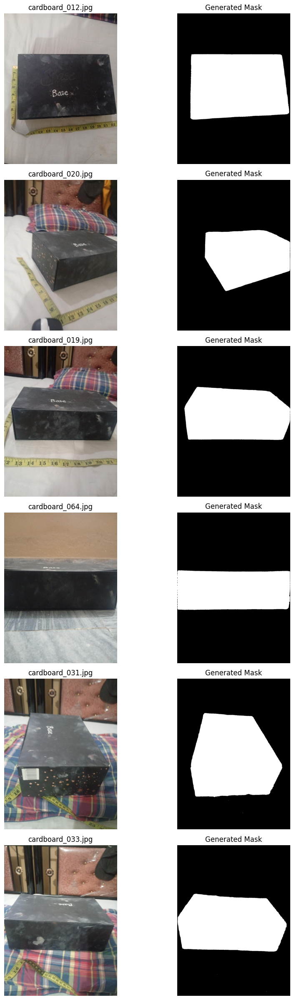

In [16]:

import os
import cv2
import matplotlib.pyplot as plt
import random

valid_pairs = []

for path in image_paths:
    name = os.path.basename(path)

    if name in {"cardboard_004.jpg", "cardboard_078.jpg"}:
        continue

    mask_path = os.path.join(
        mask_dir,
        os.path.splitext(name)[0] + "_mask.png"
    )

    if os.path.exists(mask_path):
        valid_pairs.append((path, mask_path))

print("Available image-mask pairs:", len(valid_pairs))

samples = random.sample(
    valid_pairs, min(6, len(valid_pairs))
)

fig, axes = plt.subplots(
    len(samples), 2,
    figsize=(10, 4 * len(samples)),
    squeeze=False
)

for i, (img_path, mask_path) in enumerate(samples):
    img = cv2.cvtColor(
        cv2.imread(img_path),
        cv2.COLOR_BGR2RGB
    )
    mask = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(os.path.basename(img_path))

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Generated Mask")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


In [17]:

import numpy as np
from sklearn.model_selection import train_test_split

X, Y = [], []

for img_path, mask_path in valid_pairs:
    img = cv2.imread(img_path)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if img is None or mask is None:
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (256, 256))
    mask = cv2.resize(
        mask, (256, 256),
        interpolation=cv2.INTER_NEAREST
    )

    X.append(img.astype(np.float32) / 255.0)
    Y.append((mask > 127).astype(np.float32)[..., None])

X = np.array(X)
Y = np.array(Y)

X_train, X_temp, Y_train, Y_temp = train_test_split(
    X, Y, test_size=0.30, random_state=42
)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, Y_temp, test_size=1/3, random_state=42
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))


Training: 53
Validation: 15
Testing: 8


In [18]:

import tensorflow as tf
from tensorflow.keras import layers, Model

def conv_block(x, filters):
    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)
    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)
    return x

def build_unet():
    inputs = layers.Input((256, 256, 3))

    c1 = conv_block(inputs, 16)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 32)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 64)
    p3 = layers.MaxPooling2D()(c3)

    b = conv_block(p3, 128)

    u3 = layers.Concatenate()([
        layers.UpSampling2D()(b), c3
    ])
    c4 = conv_block(u3, 64)

    u2 = layers.Concatenate()([
        layers.UpSampling2D()(c4), c2
    ])
    c5 = conv_block(u2, 32)

    u1 = layers.Concatenate()([
        layers.UpSampling2D()(c5), c1
    ])
    c6 = conv_block(u1, 16)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid"
    )(c6)

    return Model(inputs, outputs)

model = build_unet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("GPU:", tf.config.list_physical_devices("GPU"))
print("U-Net model ready!")


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
U-Net model ready!


In [19]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/cardboard_unet.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=20,
    batch_size=4,
    callbacks=callbacks,
    verbose=1
)

print("Training completed!")


Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 61s 3s/step - accuracy: 0.7565 - loss: 0.5969 - val_accuracy: 0.7623 - val_loss: 0.5427
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.7576 - loss: 0.5263 - val_accuracy: 0.7623 - val_loss: 0.4778
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.7576 - loss: 0.4647 - val_accuracy: 0.7623 - val_loss: 0.4553
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.7576 - loss: 0.4641 - val_accuracy: 0.7623 - val_loss: 0.5131
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.7576 - loss: 0.4189 - val_accuracy: 0.7623 - val_loss: 0.4445
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.7576 - loss: 0.4115 - val_accuracy: 0.7623 - val_loss: 0.6941
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.7576 - loss: 0.4738 - val_accuracy: 0.7623 - val_loss: 0.6489
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.7576 - loss: 0.4106 - val_accuracy: 0.7623 - va

In [20]:

import numpy as np

# Best saved model load karo
import tensorflow as tf

model = tf.keras.models.load_model(
    "/content/drive/MyDrive/cardboard_unet.keras"
)

predictions = model.predict(X_test, verbose=0)

pred_masks = predictions > 0.5
true_masks = Y_test > 0.5

dice_scores = []
iou_scores = []

for pred, true in zip(pred_masks, true_masks):
    intersection = np.logical_and(pred, true).sum()
    union = np.logical_or(pred, true).sum()

    dice = (2 * intersection + 1e-7) / (
        pred.sum() + true.sum() + 1e-7
    )

    iou = (intersection + 1e-7) / (
        union + 1e-7
    )

    dice_scores.append(dice)
    iou_scores.append(iou)

print("Test images:", len(X_test))
print("Mean Dice Score:", round(np.mean(dice_scores), 4))
print("Mean IoU:", round(np.mean(iou_scores), 4))


Test images: 8
Mean Dice Score: 0.0
Mean IoU: 0.0


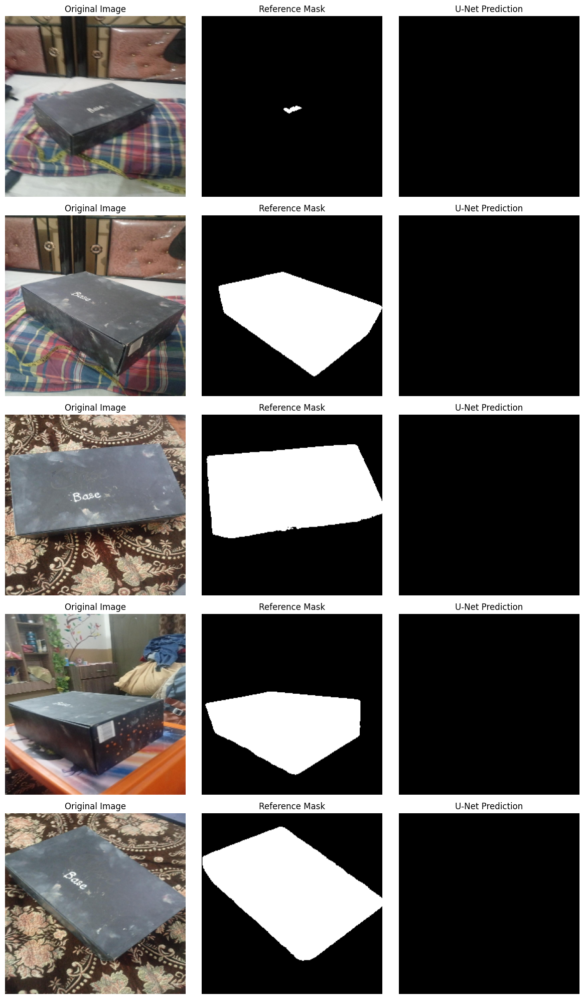

In [21]:

import matplotlib.pyplot as plt

n = min(5, len(X_test))

fig, axes = plt.subplots(
    n, 3,
    figsize=(12, 4*n),
    squeeze=False
)

for i in range(n):
    axes[i, 0].imshow(X_test[i])
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(Y_test[i].squeeze(), cmap="gray")
    axes[i, 1].set_title("Reference Mask")

    axes[i, 2].imshow(pred_masks[i].squeeze(), cmap="gray")
    axes[i, 2].set_title("U-Net Prediction")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [22]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

def measure_cardboard(image, model):
    # Image ka original size
    h, w = image.shape[:2]

    # Model input prepare
    resized = cv2.resize(image, (256, 256))
    input_img = resized.astype(np.float32) / 255.0

    # U-Net prediction
    prediction = model.predict(
        input_img[np.newaxis, ...],
        verbose=0
    )[0, :, :, 0]

    # Binary mask
    mask = (prediction > 0.5).astype(np.uint8) * 255

    # Original resolution restore
    mask = cv2.resize(
        mask, (w, h),
        interpolation=cv2.INTER_NEAREST
    )

    # Largest contour
    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return None

    contour = max(contours, key=cv2.contourArea)

    # Rotated bounding rectangle
    rect = cv2.minAreaRect(contour)
    box = cv2.boxPoints(rect).astype(np.int32)

    width_px, height_px = rect[1]

    result = image.copy()
    cv2.drawContours(result, [box], 0, (255, 0, 0), 3)

    return result, mask, width_px, height_px


In [23]:

# First test image
test_path = image_paths[0]

img_bgr = cv2.imread(test_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

result = measure_cardboard(img_rgb, model)

if result is not None:
    output, mask, width_px, height_px = result

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(output)
    plt.title("Detected Cardboard Boundary")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Predicted Segmentation Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Width (pixels):", round(width_px, 2))
    print("Height (pixels):", round(height_px, 2))
else:
    print("No cardboard detected")


No cardboard detected


Minimum prediction: 1.5910159e-07
Maximum prediction: 0.45717746
Mean prediction: 0.22319573


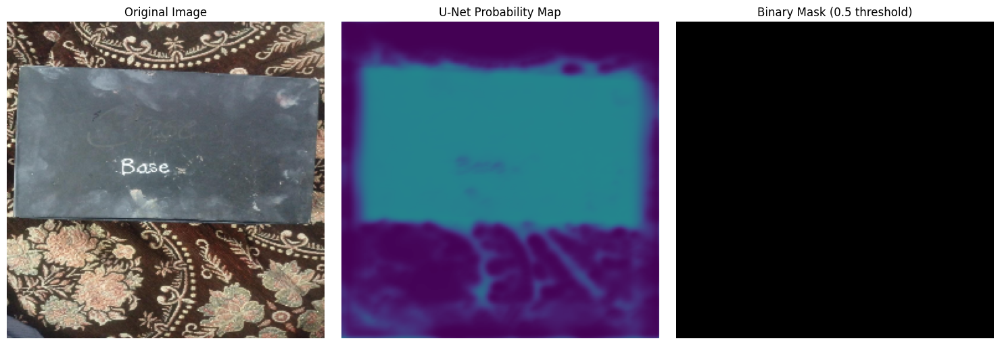

In [24]:

import numpy as np
import cv2
import matplotlib.pyplot as plt

test_path = image_paths[0]

img_bgr = cv2.imread(test_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

resized = cv2.resize(img_rgb, (256, 256))
input_img = resized.astype(np.float32) / 255.0

prediction = model.predict(
    input_img[np.newaxis, ...],
    verbose=0
)[0, :, :, 0]

print("Minimum prediction:", prediction.min())
print("Maximum prediction:", prediction.max())
print("Mean prediction:", prediction.mean())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(resized)
axes[0].set_title("Original Image")

axes[1].imshow(prediction, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("U-Net Probability Map")

axes[2].imshow(prediction > 0.5, cmap="gray")
axes[2].set_title("Binary Mask (0.5 threshold)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


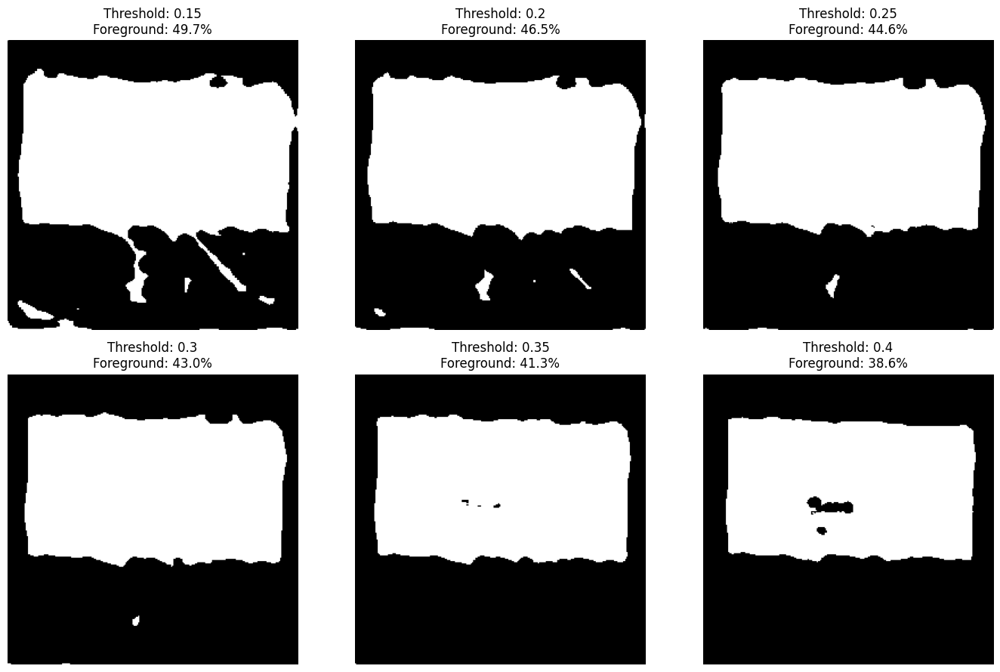

In [25]:

import matplotlib.pyplot as plt
import numpy as np

thresholds = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40]

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, threshold in zip(axes.flat, thresholds):
    binary = prediction > threshold

    ax.imshow(binary, cmap="gray")
    ax.set_title(
        f"Threshold: {threshold}\n"
        f"Foreground: {binary.mean()*100:.1f}%"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


In [26]:

import numpy as np

test_predictions = model.predict(X_val, verbose=0)

thresholds = np.arange(0.10, 0.51, 0.05)

results = []

for threshold in thresholds:
    dices = []
    ious = []

    for pred, true in zip(test_predictions, Y_val):
        p = pred[..., 0] > threshold
        t = true[..., 0] > 0.5

        intersection = np.logical_and(p, t).sum()
        union = np.logical_or(p, t).sum()

        dice = (2 * intersection + 1e-7) / (
            p.sum() + t.sum() + 1e-7
        )

        iou = (intersection + 1e-7) / (
            union + 1e-7
        )

        dices.append(dice)
        ious.append(iou)

    results.append((
        round(float(threshold), 2),
        round(float(np.mean(dices)), 4),
        round(float(np.mean(ious)), 4)
    ))

for threshold, dice, iou in results:
    print(
        f"Threshold: {threshold:.2f} | "
        f"Dice: {dice:.4f} | IoU: {iou:.4f}"
    )

best_threshold, best_dice, best_iou = max(
    results, key=lambda x: x[1]
)

print("\nBest validation threshold:", best_threshold)
print("Validation Dice:", best_dice)
print("Validation IoU:", best_iou)


Threshold: 0.10 | Dice: 0.4501 | IoU: 0.3262
Threshold: 0.15 | Dice: 0.4752 | IoU: 0.3512
Threshold: 0.20 | Dice: 0.4980 | IoU: 0.3743
Threshold: 0.25 | Dice: 0.5167 | IoU: 0.3938
Threshold: 0.30 | Dice: 0.5332 | IoU: 0.4120
Threshold: 0.35 | Dice: 0.5504 | IoU: 0.4329
Threshold: 0.40 | Dice: 0.5577 | IoU: 0.4499
Threshold: 0.45 | Dice: 0.3766 | IoU: 0.2682
Threshold: 0.50 | Dice: 0.0000 | IoU: 0.0000

Best validation threshold: 0.4
Validation Dice: 0.5577
Validation IoU: 0.4499


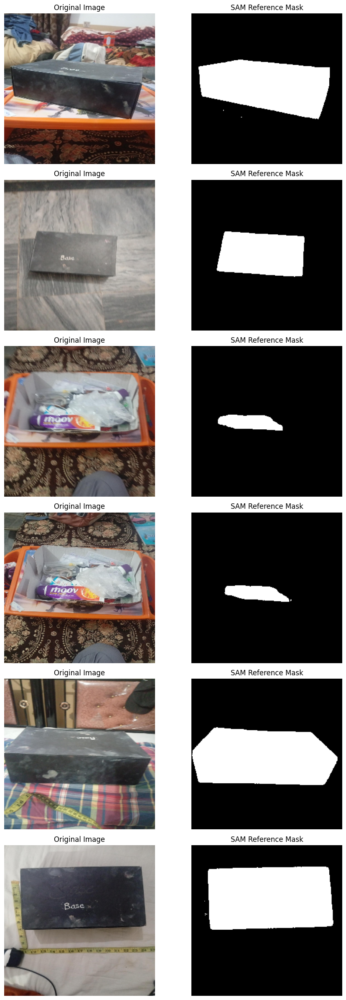

In [27]:

import matplotlib.pyplot as plt
import numpy as np

indices = np.random.choice(
    len(X_train),
    size=min(6, len(X_train)),
    replace=False
)

fig, axes = plt.subplots(
    len(indices), 2,
    figsize=(10, 4 * len(indices)),
    squeeze=False
)

for row, idx in enumerate(indices):
    axes[row, 0].imshow(X_train[idx])
    axes[row, 0].set_title("Original Image")

    axes[row, 1].imshow(
        Y_train[idx].squeeze(),
        cmap="gray"
    )
    axes[row, 1].set_title("SAM Reference Mask")

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


In [28]:

import tensorflow as tf

def dice_coefficient(y_true, y_pred, smooth=1e-6):
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true * y_pred)

    return (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true) +
        tf.reduce_sum(y_pred) +
        smooth
    )

def combined_loss(y_true, y_pred):
    bce = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(
            y_true, y_pred
        )
    )

    dice_loss = 1.0 - dice_coefficient(
        y_true, y_pred
    )

    return bce + dice_loss

print("Improved loss function ready!")


Improved loss function ready!


In [29]:

import tensorflow as tf

# Fresh model for fair comparison
improved_model = build_unet()

improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss=combined_loss,
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),
        dice_coefficient
    ]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/cardboard_unet_improved.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_improved = improved_model.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=40,
    batch_size=4,
    callbacks=callbacks,
    verbose=1
)

print("Improved training completed!")


Epoch 1/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 19s 593ms/step - accuracy: 0.7576 - dice_coefficient: 0.2969 - loss: 1.3230 - val_accuracy: 0.7623 - val_dice_coefficient: 0.2633 - val_loss: 1.2714
Epoch 2/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.7576 - dice_coefficient: 0.2755 - loss: 1.2433 - val_accuracy: 0.7623 - val_dice_coefficient: 0.2408 - val_loss: 1.2893
Epoch 3/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.7576 - dice_coefficient: 0.2940 - loss: 1.1964 - val_accuracy: 0.7623 - val_dice_coefficient: 0.3155 - val_loss: 1.1518
Epoch 4/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.7576 - dice_coefficient: 0.3425 - loss: 1.1286 - val_accuracy: 0.7623 - val_dice_coefficient: 0.3553 - val_loss: 1.0844
Epoch 5/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.7608 - dice_coefficient: 0.3840 - loss: 1.0475 - val_accuracy: 0.7573 - val_dice_coefficient: 0.3959 - val_loss: 1.0484
Epoch 6/40
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.8201 - d

In [30]:

import numpy as np

preds = improved_model.predict(X_val, verbose=0)

for threshold in [0.3, 0.4, 0.5, 0.6]:
    dices, ious = [], []

    for pred, true in zip(preds, Y_val):
        p = pred[..., 0] > threshold
        t = true[..., 0] > 0.5

        intersection = np.logical_and(p, t).sum()
        union = np.logical_or(p, t).sum()

        dice = (2 * intersection + 1e-7) / (
            p.sum() + t.sum() + 1e-7
        )
        iou = (intersection + 1e-7) / (
            union + 1e-7
        )

        dices.append(dice)
        ious.append(iou)

    print(
        f"Threshold {threshold}: "
        f"Dice={np.mean(dices):.4f}, "
        f"IoU={np.mean(ious):.4f}"
    )


Threshold 0.3: Dice=0.5799, IoU=0.4998
Threshold 0.4: Dice=0.5667, IoU=0.4812
Threshold 0.5: Dice=0.5512, IoU=0.4611
Threshold 0.6: Dice=0.5309, IoU=0.4356


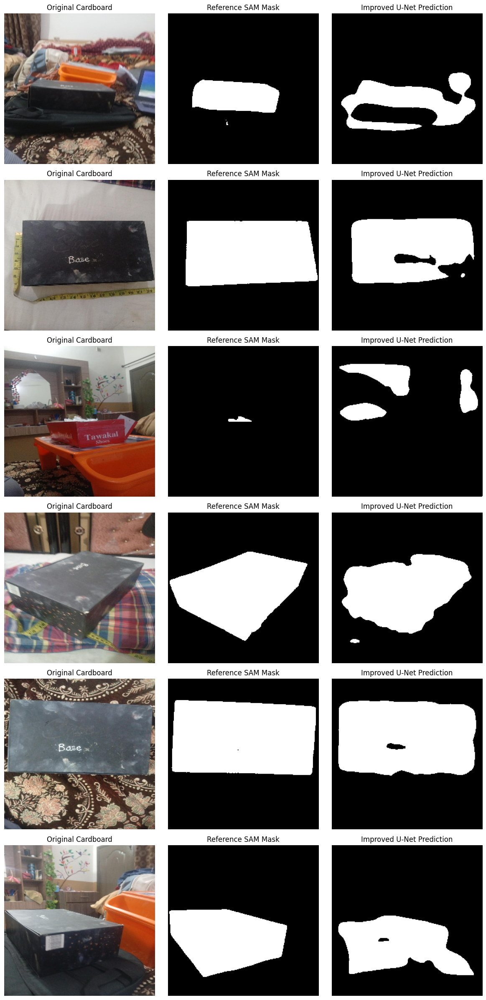

In [31]:

import numpy as np
import matplotlib.pyplot as plt

# Best validation-loss weights already restored
preds = improved_model.predict(X_val, verbose=0)

threshold = 0.30
n = min(6, len(X_val))

fig, axes = plt.subplots(
    n, 3,
    figsize=(12, 4*n),
    squeeze=False
)

for i in range(n):
    pred_mask = preds[i, :, :, 0] > threshold

    axes[i, 0].imshow(X_val[i])
    axes[i, 0].set_title("Original Cardboard")

    axes[i, 1].imshow(
        Y_val[i].squeeze(), cmap="gray"
    )
    axes[i, 1].set_title("Reference SAM Mask")

    axes[i, 2].imshow(
        pred_mask, cmap="gray"
    )
    axes[i, 2].set_title("Improved U-Net Prediction")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [32]:

results = []

for i in range(len(X_val)):
    pred = preds[i, :, :, 0] > 0.30
    true = Y_val[i, :, :, 0] > 0.5

    intersection = np.logical_and(pred, true).sum()
    union = np.logical_or(pred, true).sum()

    dice = (2 * intersection + 1e-7) / (
        pred.sum() + true.sum() + 1e-7
    )

    iou = (intersection + 1e-7) / (
        union + 1e-7
    )

    results.append((i, dice, iou))

results.sort(key=lambda x: x[1])

print("Worst 5 validation predictions:")

for idx, dice, iou in results[:5]:
    print(
        f"Image index: {idx} | "
        f"Dice: {dice:.4f} | "
        f"IoU: {iou:.4f}"
    )


Worst 5 validation predictions:
Image index: 14 | Dice: 0.0000 | IoU: 0.0000
Image index: 2 | Dice: 0.0000 | IoU: 0.0000
Image index: 7 | Dice: 0.0023 | IoU: 0.0012
Image index: 8 | Dice: 0.0056 | IoU: 0.0028
Image index: 12 | Dice: 0.3272 | IoU: 0.1956


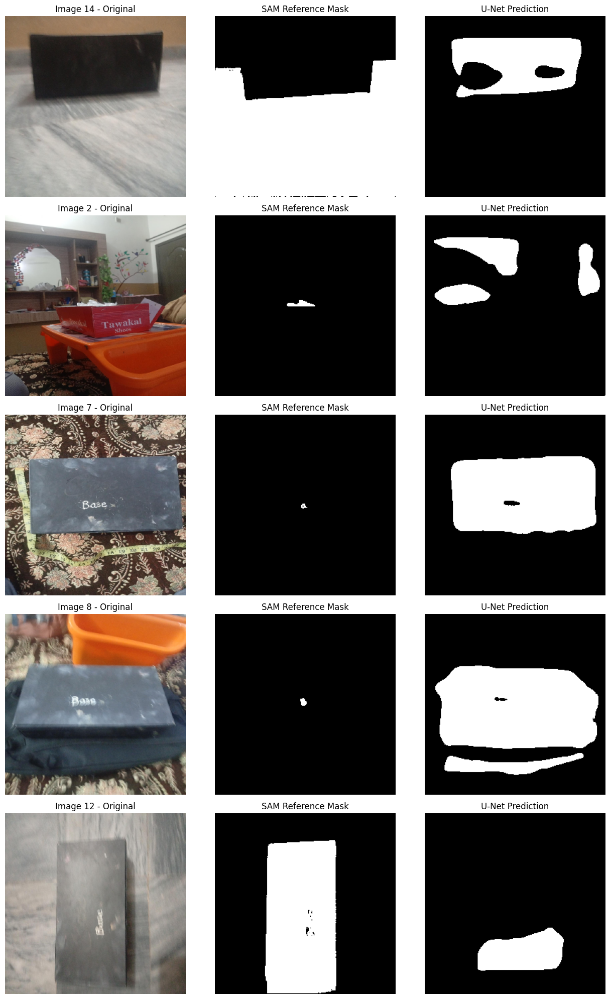

In [33]:

import numpy as np
import matplotlib.pyplot as plt

worst_indices = [14, 2, 7, 8, 12]

fig, axes = plt.subplots(
    len(worst_indices), 3,
    figsize=(13, 4 * len(worst_indices))
)

for row, idx in enumerate(worst_indices):
    original = X_val[idx]
    actual = Y_val[idx].squeeze()
    predicted = preds[idx, :, :, 0] > 0.30

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"Image {idx} - Original")

    axes[row, 1].imshow(actual, cmap="gray")
    axes[row, 1].set_title("SAM Reference Mask")

    axes[row, 2].imshow(predicted, cmap="gray")
    axes[row, 2].set_title("U-Net Prediction")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [34]:

for idx in worst_indices:
    actual = Y_val[idx].squeeze()
    predicted = preds[idx, :, :, 0] > 0.30

    print(f"\nImage {idx}")
    print("Reference foreground:", round(actual.mean()*100, 2), "%")
    print("Predicted foreground:", round(predicted.mean()*100, 2), "%")
    print("Maximum probability:", round(float(preds[idx].max()), 4))



Image 14
Reference foreground: 60.73 %
Predicted foreground: 16.96 %
Maximum probability: 0.8547

Image 2
Reference foreground: 0.33 %
Predicted foreground: 10.19 %
Maximum probability: 0.8979

Image 7
Reference foreground: 0.06 %
Predicted foreground: 31.58 %
Maximum probability: 0.9081

Image 8
Reference foreground: 0.11 %
Predicted foreground: 40.5 %
Maximum probability: 0.9076

Image 12
Reference foreground: 31.99 %
Predicted foreground: 8.5 %
Maximum probability: 0.8384


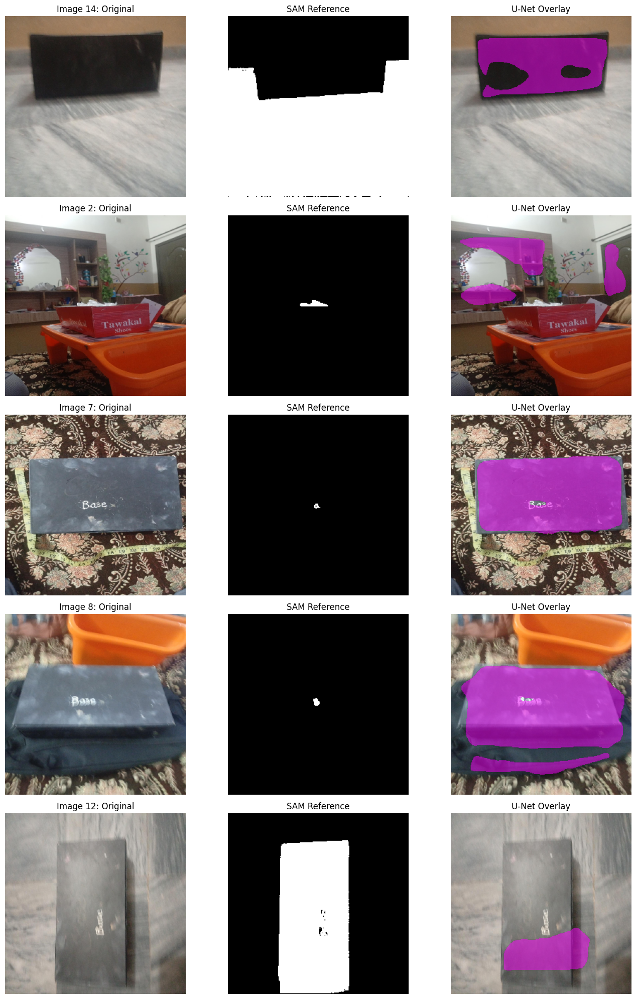

In [35]:

import matplotlib.pyplot as plt
import numpy as np

worst_indices = [14, 2, 7, 8, 12]

fig, axes = plt.subplots(
    len(worst_indices), 3,
    figsize=(14, 4 * len(worst_indices)),
    squeeze=False
)

for row, idx in enumerate(worst_indices):
    image = X_val[idx]
    reference = Y_val[idx, :, :, 0]
    predicted = preds[idx, :, :, 0] > 0.30

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Image {idx}: Original")

    axes[row, 1].imshow(reference, cmap="gray")
    axes[row, 1].set_title("SAM Reference")

    axes[row, 2].imshow(image)
    axes[row, 2].imshow(
        np.ma.masked_where(~predicted, predicted),
        cmap="spring",
        alpha=0.5
    )
    axes[row, 2].set_title("U-Net Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [36]:

import cv2
import numpy as np
import os

suspicious = []

for img_path, mask_path in valid_pairs:
    mask = cv2.imread(
        mask_path, cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        continue

    foreground = (mask > 127).mean() * 100

    if foreground < 2 or foreground > 95:
        suspicious.append((
            os.path.basename(img_path),
            round(foreground, 2)
        ))

print("Suspicious masks:", len(suspicious))

for filename, percentage in suspicious:
    print(filename, "| Foreground:", percentage, "%")


Suspicious masks: 8
cardboard_003.jpg | Foreground: 0.06 %
cardboard_011.jpg | Foreground: 0.06 %
cardboard_022.jpg | Foreground: 0.37 %
cardboard_035.jpg | Foreground: 0.21 %
cardboard_042.jpg | Foreground: 0.12 %
cardboard_061.jpg | Foreground: 0.12 %
cardboard_063.jpg | Foreground: 0.07 %
cardboard_072.jpg | Foreground: 0.33 %


In [37]:

import os

suspicious_files = {
    "cardboard_003.jpg",
    "cardboard_011.jpg",
    "cardboard_022.jpg",
    "cardboard_035.jpg",
    "cardboard_042.jpg",
    "cardboard_061.jpg",
    "cardboard_063.jpg",
    "cardboard_072.jpg"
}

clean_pairs = [
    (img_path, mask_path)
    for img_path, mask_path in valid_pairs
    if os.path.basename(img_path) not in suspicious_files
]

print("Original pairs:", len(valid_pairs))
print("Excluded:", len(valid_pairs) - len(clean_pairs))
print("Remaining pairs:", len(clean_pairs))


Original pairs: 76
Excluded: 8
Remaining pairs: 68


In [38]:

import cv2
import numpy as np
from sklearn.model_selection import train_test_split

X_clean, Y_clean = [], []

for img_path, mask_path in clean_pairs:
    img = cv2.imread(img_path)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if img is None or mask is None:
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (256, 256))
    mask = cv2.resize(
        mask, (256, 256),
        interpolation=cv2.INTER_NEAREST
    )

    X_clean.append(img.astype(np.float32) / 255.0)
    Y_clean.append(
        (mask > 127).astype(np.float32)[..., None]
    )

X_clean = np.array(X_clean, dtype=np.float32)
Y_clean = np.array(Y_clean, dtype=np.float32)

indices = np.arange(len(X_clean))

train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx, test_size=1/3, random_state=42
)

X_train, Y_train = X_clean[train_idx], Y_clean[train_idx]
X_val, Y_val = X_clean[val_idx], Y_clean[val_idx]
X_test, Y_test = X_clean[test_idx], Y_clean[test_idx]

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))


Training: 47
Validation: 14
Testing: 7


In [39]:

import tensorflow as tf

clean_model = build_unet()

clean_model.compile(
    optimizer=tf.keras.optimizers.Adam(0.0003),
    loss=combined_loss,
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        dice_coefficient
    ]
)

callbacks_clean = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/cardboard_unet_clean.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_clean = clean_model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=40,
    batch_size=4,
    callbacks=callbacks_clean,
    verbose=1
)

print("Clean dataset training completed!")


Epoch 1/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 39s 3s/step - accuracy: 0.7220 - dice_coefficient: 0.3276 - loss: 1.3140 - val_accuracy: 0.6776 - val_dice_coefficient: 0.2259 - val_loss: 1.4721
Epoch 2/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.7349 - dice_coefficient: 0.2992 - loss: 1.2693 - val_accuracy: 0.6796 - val_dice_coefficient: 0.3485 - val_loss: 1.2457
Epoch 3/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.7376 - dice_coefficient: 0.3198 - loss: 1.2086 - val_accuracy: 0.6798 - val_dice_coefficient: 0.3645 - val_loss: 1.1587
Epoch 4/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.7376 - dice_coefficient: 0.3742 - loss: 1.1211 - val_accuracy: 0.6798 - val_dice_coefficient: 0.4273 - val_loss: 1.0449
Epoch 5/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.7376 - dice_coefficient: 0.3965 - loss: 1.0615 - val_accuracy: 0.6798 - val_dice_coefficient: 0.3915 - val_loss: 1.1063
Epoch 6/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.7401 - dice

In [40]:

import numpy as np

# Validation predictions
val_preds = clean_model.predict(X_val, verbose=0)

thresholds = np.arange(0.20, 0.71, 0.05)

results = []

for threshold in thresholds:
    dices = []
    ious = []

    for pred, true in zip(val_preds, Y_val):
        p = pred[..., 0] > threshold
        t = true[..., 0] > 0.5

        intersection = np.logical_and(p, t).sum()
        union = np.logical_or(p, t).sum()

        dice = (2 * intersection + 1e-7) / (
            p.sum() + t.sum() + 1e-7
        )

        iou = (intersection + 1e-7) / (
            union + 1e-7
        )

        dices.append(dice)
        ious.append(iou)

    results.append((
        round(float(threshold), 2),
        round(float(np.mean(dices)), 4),
        round(float(np.mean(ious)), 4)
    ))

for threshold, dice, iou in results:
    print(
        f"Threshold {threshold:.2f}: "
        f"Dice={dice:.4f}, IoU={iou:.4f}"
    )

best_threshold, best_dice, best_iou = max(
    results, key=lambda x: x[1]
)

print("\nBest threshold:", best_threshold)
print("Validation Dice:", best_dice)
print("Validation IoU:", best_iou)


Threshold 0.20: Dice=0.7408, IoU=0.6363
Threshold 0.25: Dice=0.7529, IoU=0.6542
Threshold 0.30: Dice=0.7603, IoU=0.6655
Threshold 0.35: Dice=0.7642, IoU=0.6710
Threshold 0.40: Dice=0.7665, IoU=0.6735
Threshold 0.45: Dice=0.7680, IoU=0.6746
Threshold 0.50: Dice=0.7684, IoU=0.6743
Threshold 0.55: Dice=0.7680, IoU=0.6732
Threshold 0.60: Dice=0.7679, IoU=0.6721
Threshold 0.65: Dice=0.7673, IoU=0.6701
Threshold 0.70: Dice=0.7633, IoU=0.6629

Best threshold: 0.5
Validation Dice: 0.7684
Validation IoU: 0.6743


In [41]:

test_preds = clean_model.predict(X_test, verbose=0)

test_dices = []
test_ious = []

for pred, true in zip(test_preds, Y_test):
    p = pred[..., 0] > best_threshold
    t = true[..., 0] > 0.5

    intersection = np.logical_and(p, t).sum()
    union = np.logical_or(p, t).sum()

    dice = (2 * intersection + 1e-7) / (
        p.sum() + t.sum() + 1e-7
    )

    iou = (intersection + 1e-7) / (
        union + 1e-7
    )

    test_dices.append(dice)
    test_ious.append(iou)

print("Test images:", len(X_test))
print("Test Dice:", round(np.mean(test_dices), 4))
print("Test IoU:", round(np.mean(test_ious), 4))


Test images: 7
Test Dice: 0.6099
Test IoU: 0.5243


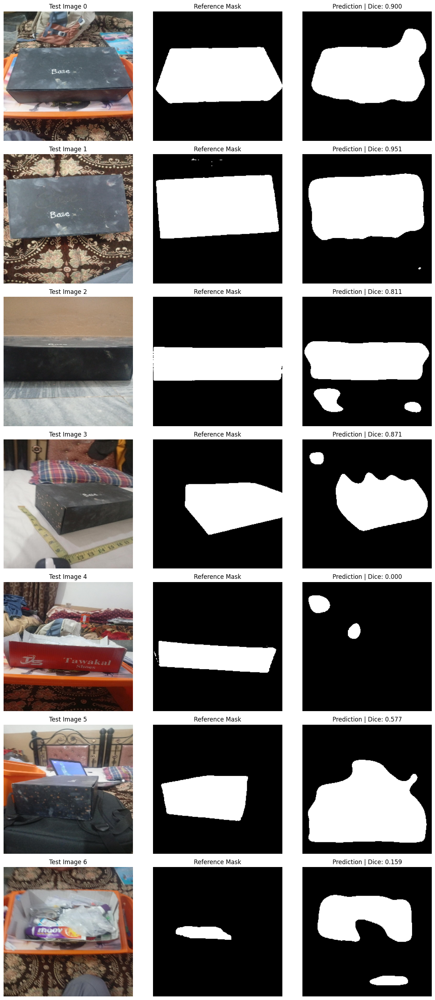

In [43]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    len(X_test), 3,
    figsize=(13, 4 * len(X_test)),
    squeeze=False
)

for i in range(len(X_test)):
    predicted = test_preds[i, :, :, 0] > 0.5
    actual = Y_test[i, :, :, 0] > 0.5

    intersection = np.logical_and(predicted, actual).sum()

    dice = (2 * intersection + 1e-7) / (
        predicted.sum() + actual.sum() + 1e-7
    )

    axes[i, 0].imshow(X_test[i])
    axes[i, 0].set_title(f"Test Image {i}")

    axes[i, 1].imshow(actual, cmap="gray")
    axes[i, 1].set_title("Reference Mask")

    axes[i, 2].imshow(predicted, cmap="gray")
    axes[i, 2].set_title(f"Prediction | Dice: {dice:.3f}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


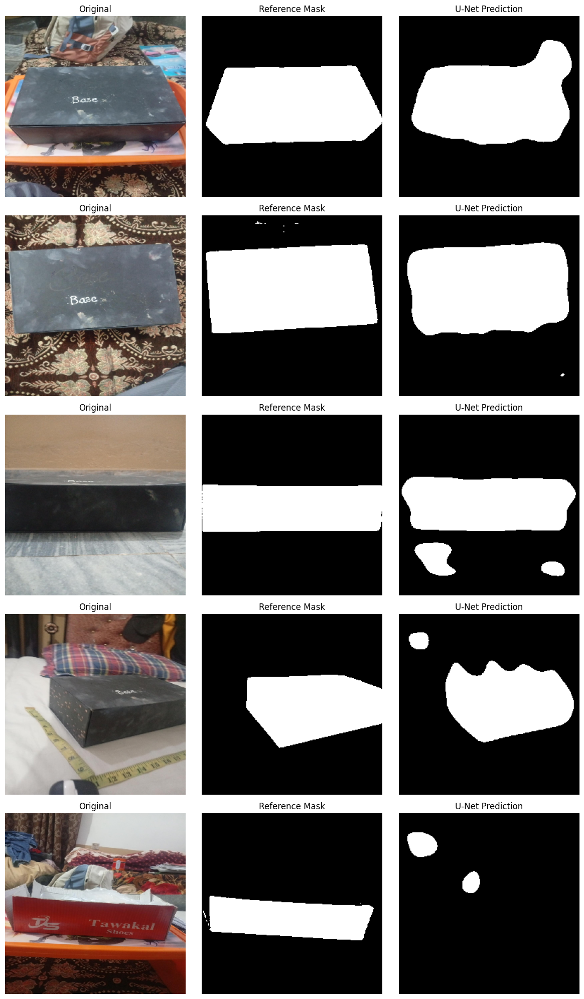

In [42]:

import matplotlib.pyplot as plt

n = min(5, len(X_test))

fig, axes = plt.subplots(
    n, 3,
    figsize=(12, 4*n),
    squeeze=False
)

for i in range(n):
    predicted = test_preds[i, :, :, 0] > best_threshold

    axes[i, 0].imshow(X_test[i])
    axes[i, 0].set_title("Original")

    axes[i, 1].imshow(
        Y_test[i].squeeze(), cmap="gray"
    )
    axes[i, 1].set_title("Reference Mask")

    axes[i, 2].imshow(
        predicted, cmap="gray"
    )
    axes[i, 2].set_title("U-Net Prediction")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


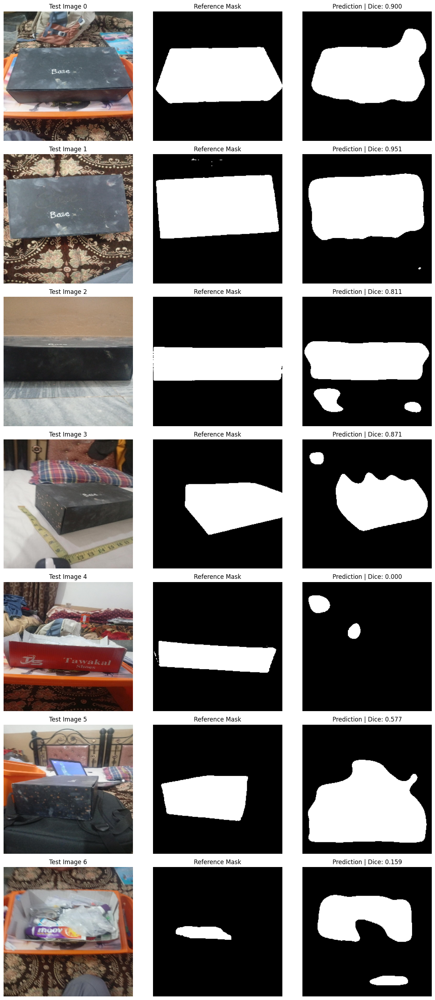

In [44]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    len(X_test), 3,
    figsize=(13, 4 * len(X_test)),
    squeeze=False
)

for i in range(len(X_test)):
    predicted = test_preds[i, :, :, 0] > 0.5
    actual = Y_test[i, :, :, 0] > 0.5

    intersection = np.logical_and(predicted, actual).sum()

    dice = (2 * intersection + 1e-7) / (
        predicted.sum() + actual.sum() + 1e-7
    )

    axes[i, 0].imshow(X_test[i])
    axes[i, 0].set_title(f"Test Image {i}")

    axes[i, 1].imshow(actual, cmap="gray")
    axes[i, 1].set_title("Reference Mask")

    axes[i, 2].imshow(predicted, cmap="gray")
    axes[i, 2].set_title(f"Prediction | Dice: {dice:.3f}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [45]:

scores = []

for i in range(len(X_test)):
    predicted = test_preds[i, :, :, 0] > 0.5
    actual = Y_test[i, :, :, 0] > 0.5

    intersection = np.logical_and(predicted, actual).sum()

    dice = (2 * intersection + 1e-7) / (
        predicted.sum() + actual.sum() + 1e-7
    )

    scores.append((i, float(dice)))

scores.sort(key=lambda x: x[1])

print("Test images ranked from worst to best:")

for idx, dice in scores:
    print(f"Image {idx}: Dice = {dice:.4f}")


Test images ranked from worst to best:
Image 4: Dice = 0.0000
Image 6: Dice = 0.1592
Image 5: Dice = 0.5766
Image 2: Dice = 0.8114
Image 3: Dice = 0.8708
Image 0: Dice = 0.9004
Image 1: Dice = 0.9507


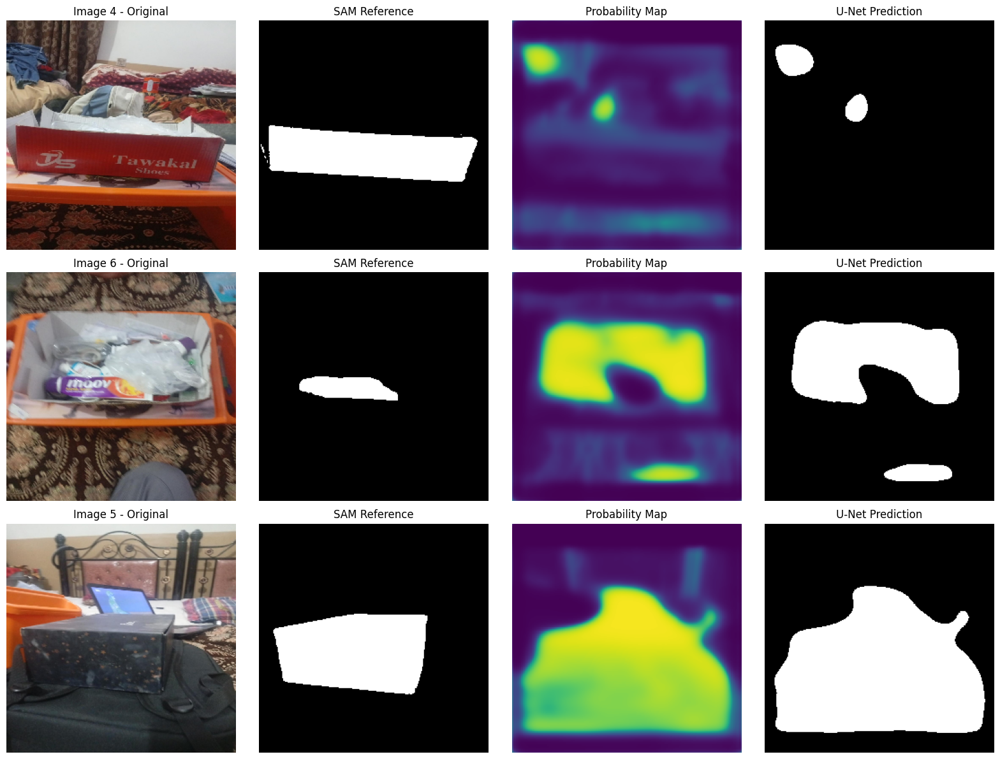

In [46]:

import numpy as np
import matplotlib.pyplot as plt

problem_indices = [4, 6, 5]

fig, axes = plt.subplots(
    len(problem_indices), 4,
    figsize=(16, 4 * len(problem_indices)),
    squeeze=False
)

for row, idx in enumerate(problem_indices):
    image = X_test[idx]
    reference = Y_test[idx, :, :, 0] > 0.5
    probability = test_preds[idx, :, :, 0]
    predicted = probability > 0.5

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Image {idx} - Original")

    axes[row, 1].imshow(reference, cmap="gray")
    axes[row, 1].set_title("SAM Reference")

    axes[row, 2].imshow(
        probability, cmap="viridis", vmin=0, vmax=1
    )
    axes[row, 2].set_title("Probability Map")

    axes[row, 3].imshow(predicted, cmap="gray")
    axes[row, 3].set_title("U-Net Prediction")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [50]:

for idx in [4, 6, 5]:
    reference = Y_test[idx, :, :, 0] > 0.5
    probability = test_preds[idx, :, :, 0]
    predicted = probability > 0.5

    print(f"\nImage {idx}")

    print(
        "Reference foreground:",
        round(reference.mean() * 100, 2), "%"
    )

    print(
        "Predicted foreground:",
        round(predicted.mean() * 100, 2), "%"
    )

    print(
        "Maximum probability:",
        round(float(probability.max()), 4)
    )



Image 4
Reference foreground: 16.8 %
Predicted foreground: 2.71 %
Maximum probability: 0.9233

Image 6
Reference foreground: 3.34 %
Predicted foreground: 22.37 %
Maximum probability: 0.979

Image 5
Reference foreground: 19.44 %
Predicted foreground: 44.06 %
Maximum probability: 0.9881


In [51]:

import os

print("Problematic test images:\n")

for idx in [4, 6, 5]:
    original_index = test_idx[idx]
    img_path, mask_path = clean_pairs[original_index]

    print(f"Test Image {idx}")
    print("Filename:", os.path.basename(img_path))
    print("Mask:", os.path.basename(mask_path))
    print("-" * 35)


Problematic test images:

Test Image 4
Filename: cardboard_070.jpg
Mask: cardboard_070_mask.png
-----------------------------------
Test Image 6
Filename: cardboard_075.jpg
Mask: cardboard_075_mask.png
-----------------------------------
Test Image 5
Filename: cardboard_048.jpg
Mask: cardboard_048_mask.png
-----------------------------------


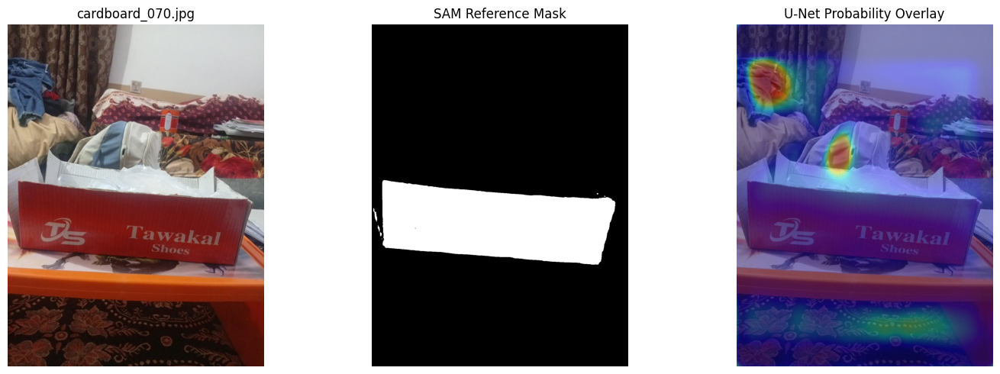

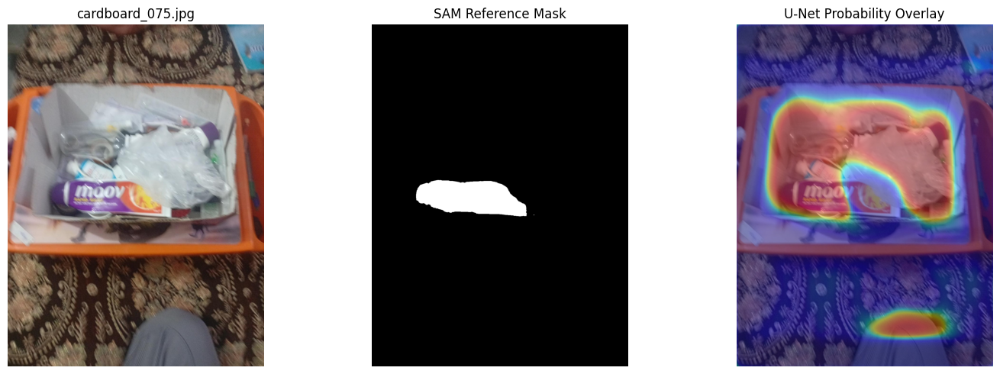

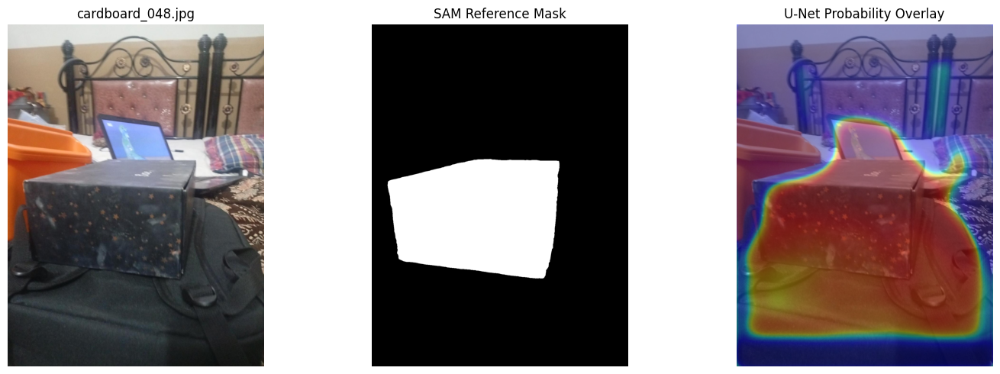

In [52]:

import cv2
import matplotlib.pyplot as plt

for idx in [4, 6, 5]:
    original_index = test_idx[idx]
    img_path, mask_path = clean_pairs[original_index]

    image = cv2.cvtColor(
        cv2.imread(img_path),
        cv2.COLOR_BGR2RGB
    )

    mask = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image)
    axes[0].set_title(os.path.basename(img_path))

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("SAM Reference Mask")

    axes[2].imshow(image)
    axes[2].imshow(
        cv2.resize(
            test_preds[idx, :, :, 0],
            (image.shape[1], image.shape[0])
        ),
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    axes[2].set_title("U-Net Probability Overlay")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


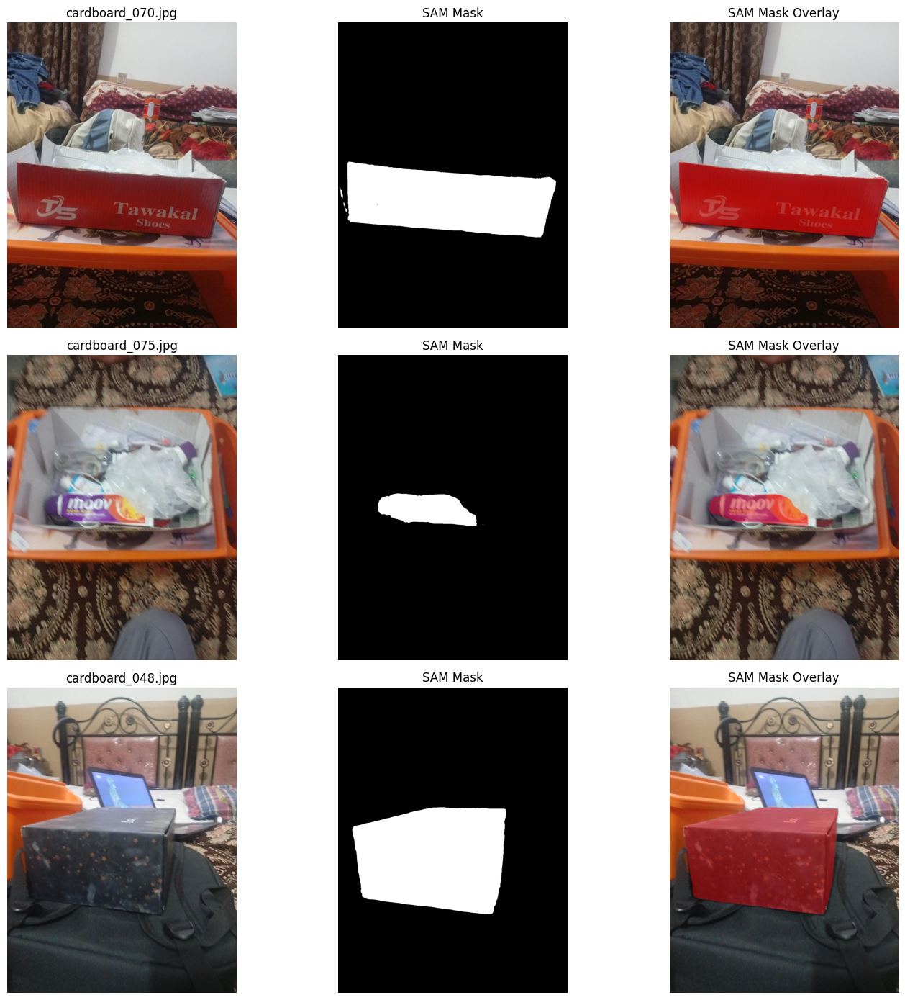

In [53]:

import cv2
import os
import matplotlib.pyplot as plt
import numpy as np

files_to_check = [
    "cardboard_070.jpg",
    "cardboard_075.jpg",
    "cardboard_048.jpg"
]

fig, axes = plt.subplots(3, 3, figsize=(15, 14))

for row, filename in enumerate(files_to_check):

    pair = next(
        (p for p in clean_pairs
         if os.path.basename(p[0]) == filename),
        None
    )

    if pair is None:
        continue

    img_path, mask_path = pair

    image = cv2.cvtColor(
        cv2.imread(img_path),
        cv2.COLOR_BGR2RGB
    )

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask = mask > 127

    overlay = image.copy()
    overlay[mask] = (
        0.6 * overlay[mask] +
        0.4 * np.array([255, 0, 0])
    ).astype(np.uint8)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(filename)

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title("SAM Mask")

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title("SAM Mask Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


yes


yes


     CARDBOARD SEGMENTATION - FINAL PROJECT REPORT

[1] DATASET INFORMATION
Original images: 78
Generated SAM masks: 76
Clean image-mask pairs: 68

Training images: 47
Validation images: 14
Testing images: 7

[2] SAVED MODEL CHECK
Model saved successfully!
Path: /content/drive/MyDrive/cardboard_unet_clean.keras
Size: 5.69 MB

[3] MODEL EVALUATION

VALIDATION RESULTS
Dice: 0.7684
IoU: 0.6743
Pixel Accuracy: 85.68 %

TEST RESULTS
Dice: 0.6099
IoU: 0.5243
Pixel Accuracy: 86.34 %

[4] INDIVIDUAL TEST IMAGE RESULTS
cardboard_053.jpg | Dice: 0.9004 | IoU: 0.8188
cardboard_010.jpg | Dice: 0.9507 | IoU: 0.9060
cardboard_064.jpg | Dice: 0.8114 | IoU: 0.6827
cardboard_020.jpg | Dice: 0.8708 | IoU: 0.7711
cardboard_070.jpg | Dice: 0.0000 | IoU: 0.0000
cardboard_048.jpg | Dice: 0.5766 | IoU: 0.4051
cardboard_075.jpg | Dice: 0.1592 | IoU: 0.0865

[5] TEST IMAGE VISUALIZATION


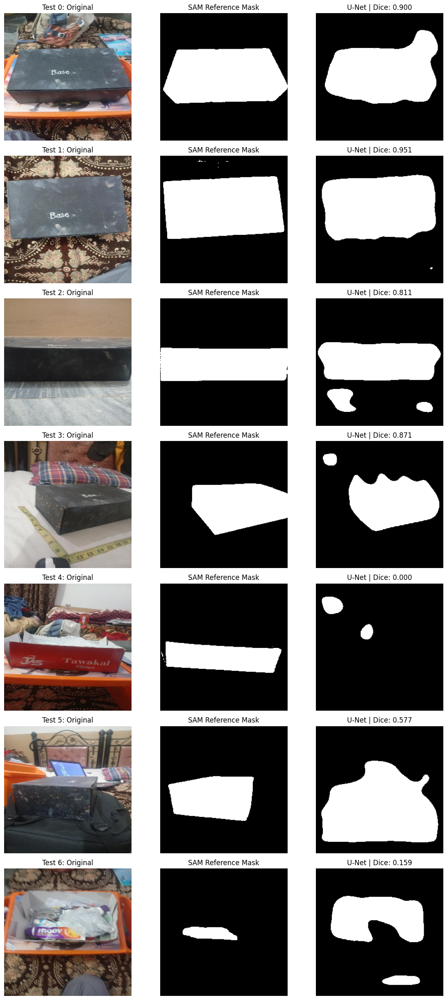


FINAL PROJECT SUMMARY
Model: U-Net
Segmentation reference: SAM
Image resolution: 256 x 256
Threshold: 0.5
Validation Dice: 0.7684
Validation IoU: 0.6743
Test Dice: 0.6099
Test IoU: 0.5243

Weak test images (Dice < 0.60):
cardboard_070.jpg | Dice: 0.0
cardboard_048.jpg | Dice: 0.5766
cardboard_075.jpg | Dice: 0.1592

NOTE: Physical dimensions in mm are not evaluated.
NOTE: SAM masks require manual quality verification.

FINAL RECHECK COMPLETED!


In [55]:

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

print("=" * 65)
print("     CARDBOARD SEGMENTATION - FINAL PROJECT REPORT")
print("=" * 65)

# 1. Dataset information
print("\n[1] DATASET INFORMATION")

print("Original images:", len(image_paths))
print("Generated SAM masks:", len(valid_pairs))
print("Clean image-mask pairs:", len(clean_pairs))

print("\nTraining images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

# 2. Saved model
print("\n[2] SAVED MODEL CHECK")

model_path = "/content/drive/MyDrive/cardboard_unet_clean.keras"

if os.path.exists(model_path):
    print("Model saved successfully!")
    print("Path:", model_path)
    print("Size:", round(os.path.getsize(model_path)/1024**2, 2), "MB")
else:
    print("WARNING: Saved model not found!")

# 3. Model predictions
print("\n[3] MODEL EVALUATION")

val_predictions = clean_model.predict(
    X_val, batch_size=4, verbose=0
)

test_predictions = clean_model.predict(
    X_test, batch_size=4, verbose=0
)

threshold = 0.50

def calculate_metrics(predictions, targets, threshold=0.50):
    dices = []
    ious = []
    accuracies = []

    for pred, target in zip(predictions, targets):
        p = pred[..., 0] > threshold
        t = target[..., 0] > 0.5

        intersection = np.logical_and(p, t).sum()
        union = np.logical_or(p, t).sum()

        dice = (2 * intersection + 1e-7) / (
            p.sum() + t.sum() + 1e-7
        )

        iou = (intersection + 1e-7) / (
            union + 1e-7
        )

        accuracy = np.mean(p == t)

        dices.append(float(dice))
        ious.append(float(iou))
        accuracies.append(float(accuracy))

    return {
        "dice": np.array(dices),
        "iou": np.array(ious),
        "accuracy": np.array(accuracies)
    }

val_metrics = calculate_metrics(
    val_predictions, Y_val, threshold
)

test_metrics = calculate_metrics(
    test_predictions, Y_test, threshold
)

print("\nVALIDATION RESULTS")
print("Dice:", round(val_metrics["dice"].mean(), 4))
print("IoU:", round(val_metrics["iou"].mean(), 4))
print("Pixel Accuracy:",
      round(val_metrics["accuracy"].mean()*100, 2), "%")

print("\nTEST RESULTS")
print("Dice:", round(test_metrics["dice"].mean(), 4))
print("IoU:", round(test_metrics["iou"].mean(), 4))
print("Pixel Accuracy:",
      round(test_metrics["accuracy"].mean()*100, 2), "%")

# 4. Individual test results
print("\n[4] INDIVIDUAL TEST IMAGE RESULTS")

for i in range(len(X_test)):
    filename = "Unknown"

    if "test_idx" in globals() and "clean_pairs" in globals():
        filename = os.path.basename(
            clean_pairs[test_idx[i]][0]
        )

    print(
        f"{filename} | "
        f"Dice: {test_metrics['dice'][i]:.4f} | "
        f"IoU: {test_metrics['iou'][i]:.4f}"
    )

# 5. Visualization
print("\n[5] TEST IMAGE VISUALIZATION")

n = len(X_test)

fig, axes = plt.subplots(
    n, 3,
    figsize=(12, 3.5*n),
    squeeze=False
)

for i in range(n):
    original = X_test[i]
    reference = Y_test[i, :, :, 0]
    prediction = test_predictions[i, :, :, 0] > threshold

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f"Test {i}: Original")

    axes[i, 1].imshow(reference, cmap="gray")
    axes[i, 1].set_title("SAM Reference Mask")

    axes[i, 2].imshow(prediction, cmap="gray")
    axes[i, 2].set_title(
        f"U-Net | Dice: {test_metrics['dice'][i]:.3f}"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

# 6. Final summary
print("\n" + "=" * 65)
print("FINAL PROJECT SUMMARY")
print("=" * 65)

print("Model: U-Net")
print("Segmentation reference: SAM")
print("Image resolution: 256 x 256")
print("Threshold:", threshold)

print("Validation Dice:",
      round(val_metrics["dice"].mean(), 4))
print("Validation IoU:",
      round(val_metrics["iou"].mean(), 4))

print("Test Dice:",
      round(test_metrics["dice"].mean(), 4))
print("Test IoU:",
      round(test_metrics["iou"].mean(), 4))

print("\nWeak test images (Dice < 0.60):")

for i, dice in enumerate(test_metrics["dice"]):
    if dice < 0.60:
        print(
            os.path.basename(clean_pairs[test_idx[i]][0]),
            "| Dice:", round(float(dice), 4)
        )

print("\nNOTE: Physical dimensions in mm are not evaluated.")
print("NOTE: SAM masks require manual quality verification.")

print("\nFINAL RECHECK COMPLETED!")


In [56]:

import os
from pathlib import Path

folders = [
    "/content",
    "/content/drive/MyDrive"
]

for folder in folders:
    print(f"\nChecking: {folder}")

    if not os.path.exists(folder):
        continue

    for item in Path(folder).iterdir():
        if item.is_dir():
            images = [
                p for p in item.rglob("*")
                if p.suffix.lower() in [
                    ".jpg", ".jpeg", ".png"
                ]
            ]

            if images:
                print(
                    item.name,
                    "| Images:", len(images)
                )



Checking: /content
segmentation_masks | Images: 76
cardboard_dataset | Images: 78
drive | Images: 173

Checking: /content/drive/MyDrive
youtube | Images: 14
Google AI Studio | Images: 1
cardboard_dataset | Images: 78
segmentation_masks | Images: 76


In [57]:

import os

root = "/content/drive/MyDrive"

print("SEARCHING FOR CALIBRATION FILES\n")

keywords = [
    "calib", "checker", "chess",
    "charuco", "camera", "board"
]

matches = []

for folder, dirs, files in os.walk(root):
    for filename in files:
        if any(word in filename.lower() for word in keywords):
            matches.append(os.path.join(folder, filename))

    for dirname in dirs:
        if any(word in dirname.lower() for word in keywords):
            matches.append(os.path.join(folder, dirname))

if matches:
    for path in matches[:100]:
        print(path)
    print("\nTotal matches:", len(matches))
else:
    print("No calibration-related files found.")

print("\nCHECKING SAVED CALIBRATION PARAMETERS")

for filename in [
    "camera_calibration.npz",
    "calibration.npz",
    "camera_matrix.npy",
    "dist_coeffs.npy"
]:
    for folder in [
        "/content",
        "/content/drive/MyDrive"
    ]:
        path = os.path.join(folder, filename)
        if os.path.isfile(path):
            print("FOUND:", path)


SEARCHING FOR CALIBRATION FILES

/content/drive/MyDrive/cardboard_unet.keras
/content/drive/MyDrive/cardboard_unet_improved.keras
/content/drive/MyDrive/cardboard_unet_clean.keras
/content/drive/MyDrive/cardboard_dataset
/content/drive/MyDrive/Colab Notebooks/camera_calibration.ipynb
/content/drive/MyDrive/Colab Notebooks/cardboard_segmentation.ipynb
/content/drive/MyDrive/cardboard_dataset/images/cardboard_039.jpg
/content/drive/MyDrive/cardboard_dataset/images/cardboard_063.jpg
/content/drive/MyDrive/cardboard_dataset/images/cardboard_040.jpg
/content/drive/MyDrive/cardboard_dataset/images/cardboard_012.jpg
/content/drive/MyDrive/cardboard_dataset/images/cardboard_016.jpg
/content/drive/MyDrive/cardboard_dataset/images/cardboard_071.jpg
/content/drive/MyDrive/cardboard_dataset/images/cardboard_041.jpg
/content/drive/MyDrive/cardboard_dataset/images/cardboard_070.jpg
/content/drive/MyDrive/cardboard_dataset/images/cardboard_054.jpg
/content/drive/MyDrive/cardboard_dataset/images/cardb

In [58]:

import json
import os

path = "/content/drive/MyDrive/Colab Notebooks/camera_calibration.ipynb"

if not os.path.exists(path):
    print("Notebook not found!")
else:
    with open(path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    print("CAMERA CALIBRATION NOTEBOOK")
    print("=" * 55)
    print("Total cells:", len(notebook.get("cells", [])))

    keywords = [
        "calibrateCamera",
        "findChessboardCorners",
        "camera_matrix",
        "dist_coeffs",
        "reprojection",
        "undistort",
        "checkerboard",
        "np.save",
        "np.savez"
    ]

    for i, cell in enumerate(notebook["cells"]):
        source = "".join(cell.get("source", []))
        found = [
            word for word in keywords
            if word.lower() in source.lower()
        ]

        if found:
            print(f"\nCELL {i+1}")
            print("Keywords:", ", ".join(found))
            print("CODE:")
            print(source[:1500])

            outputs = cell.get("outputs", [])
            for output in outputs:
                result = "".join(
                    output.get("text", [])
                )
                if result:
                    print("OUTPUT:", result[:700])


CAMERA CALIBRATION NOTEBOOK
Total cells: 1

CELL 1
Keywords: calibrateCamera, findChessboardCorners, camera_matrix, dist_coeffs, checkerboard
CODE:

import cv2
import numpy as np
import zipfile
import glob
from google.colab import files

# Upload synthetic checkerboard ZIP
uploaded = files.upload()
zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("calibration_images")

images = glob.glob("calibration_images/**/*.jpg", recursive=True)

# Expected 9 x 6 inner corners — verify pattern first
pattern_size = (9, 6)
objpoints = []
imgpoints = []

objp = np.zeros((9 * 6, 3), np.float32)
objp[:, :2] = np.mgrid[0:9, 0:6].T.reshape(-1, 2)

image_size = None

for path in images:
    img = cv2.imread(path)
    if img is None:
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    image_size = gray.shape[::-1]

    found, corners = cv2.findChessboardCorners(
        gray, pattern_size
    )

    if found:
        corners = cv2.cornerSubPix(


In [59]:

from google.colab import files
import zipfile
import os
import glob

uploaded = files.upload()

zip_name = next(iter(uploaded))

folder = "/content/real_calibration_images"
os.makedirs(folder, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall(folder)

images = []
for ext in ["jpg", "jpeg", "png", "JPG", "JPEG", "PNG"]:
    images.extend(glob.glob(
        f"{folder}/**/*.{ext}", recursive=True
    ))

print("Total calibration photos:", len(images))
print("First 5 images:")
for path in images[:5]:
    print(os.path.basename(path))


Saving checkerboard_opencv_practice.zip to checkerboard_opencv_practice.zip
Total calibration photos: 20
First 5 images:
checkerboard_09.jpg
checkerboard_14.jpg
checkerboard_01.jpg
checkerboard_17.jpg
checkerboard_02.jpg


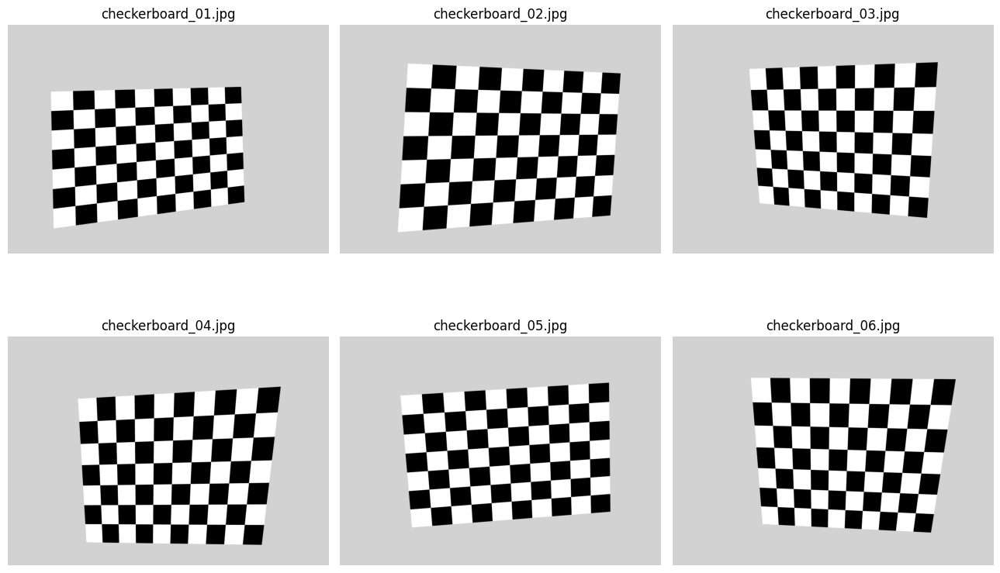

In [60]:

import cv2
import matplotlib.pyplot as plt
import os

sample_images = sorted(images)[:6]

fig, axes = plt.subplots(2, 3, figsize=(13, 9))

for ax, path in zip(axes.flat, sample_images):
    img = cv2.imread(path)

    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(os.path.basename(path))

    ax.axis("off")

plt.tight_layout()
plt.show()


In [61]:

import os, glob, json, hashlib
import cv2
import numpy as np
import tensorflow as tf

from pathlib import Path
from datetime import datetime, timezone

OUT = Path("/content/drive/MyDrive/cardboard_final_submission")
OUT.mkdir(parents=True, exist_ok=True)

# A. SYNTHETIC CALIBRATION PRACTICE
calib_files = sorted(
    glob.glob("/content/real_calibration_images/**/*.jpg", recursive=True)
)

pattern = (9, 6)
objp = np.zeros((pattern[0]*pattern[1], 3), np.float32)
objp[:, :2] = np.mgrid[
    0:pattern[0], 0:pattern[1]
].T.reshape(-1, 2)

objpoints, imgpoints = [], []
image_size = None

for path in calib_files:
    img = cv2.imread(path)
    if img is None:
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    found, corners = cv2.findChessboardCorners(gray, pattern)

    if found:
        corners = cv2.cornerSubPix(
            gray, corners, (11, 11), (-1, -1),
            (cv2.TERM_CRITERIA_EPS +
             cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
        )
        objpoints.append(objp.copy())
        imgpoints.append(corners)
        image_size = gray.shape[::-1]

if len(objpoints) >= 5:
    rms, K, dist, _, _ = cv2.calibrateCamera(
        objpoints, imgpoints, image_size, None, None
    )
    np.savez(
        OUT / "synthetic_calibration_practice.npz",
        camera_matrix=K,
        dist_coeffs=dist,
        rms=rms
    )
    print("Synthetic calibration RMS:", round(rms, 4))
    print("Valid patterns:", len(objpoints))
else:
    print("Insufficient checkerboard detections")

# B. SEGMENTATION METRICS
pred = clean_model.predict(X_test, verbose=0)
gt = np.asarray(Y_test) > 0.5
binary = pred > 0.5

tp = np.logical_and(binary, gt).sum(axis=(1,2,3))
fp = np.logical_and(binary, ~gt).sum(axis=(1,2,3))
fn = np.logical_and(~binary, gt).sum(axis=(1,2,3))

precision = tp / np.maximum(tp + fp, 1)
recall = tp / np.maximum(tp + fn, 1)
iou = tp / np.maximum(tp + fp + fn, 1)
dice = 2*tp / np.maximum(2*tp + fp + fn, 1)

rows = []

for i in range(len(X_test)):
    name = Path(clean_pairs[test_idx[i]][0]).name
    rows.append({
        "filename": name,
        "dice": float(dice[i]),
        "iou": float(iou[i]),
        "precision": float(precision[i]),
        "recall": float(recall[i])
    })

import csv
with open(OUT / "test_metrics.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

print("\nTEST METRICS")
print("Dice:", round(float(dice.mean()), 4))
print("IoU:", round(float(iou.mean()), 4))
print("Precision:", round(float(precision.mean()), 4))
print("Recall:", round(float(recall.mean()), 4))

# C. SAVE SPLIT MANIFEST (CURRENT SPLIT)
manifest = {
    "train": [Path(clean_pairs[i][0]).name for i in train_idx],
    "validation": [Path(clean_pairs[i][0]).name for i in val_idx],
    "test": [Path(clean_pairs[i][0]).name for i in test_idx]
}

with open(OUT / "split_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

# D. MODEL HASH
model_path = Path("/content/drive/MyDrive/cardboard_unet_clean.keras")

if model_path.exists():
    sha = hashlib.sha256()
    with open(model_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024*1024), b""):
            sha.update(chunk)
    model_hash = sha.hexdigest()
    print("\nModel SHA-256:", model_hash)
else:
    model_hash = None

# E. HONEST STATUS REPORT
report = {
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "original_images": 78,
    "sam_masks": 76,
    "clean_pairs": 68,
    "training_images": len(X_train),
    "validation_images": len(X_val),
    "test_images": len(X_test),
    "test_mean_dice": float(dice.mean()),
    "test_mean_iou": float(iou.mean()),
    "test_mean_precision": float(precision.mean()),
    "test_mean_recall": float(recall.mean()),
    "model_sha256": model_hash,
    "calibration": "Synthetic checkerboard practice only",
    "real_camera_calibration": "Not completed",
    "millimetre_measurement": "Not completed",
    "physical_accuracy_validation": "Not completed",
    "map_metrics": "Not yet calculated",
    "split_note": "Manifest exported after training; not evidence of a pre-training commit"
}

with open(OUT / "project_status.json", "w") as f:
    json.dump(report, f, indent=2)

print("\nFILES SAVED TO:", OUT)
for p in sorted(OUT.iterdir()):
    print(" -", p.name)

print("\nSTEP COMPLETED")


Synthetic calibration RMS: 6.2619
Valid patterns: 20

TEST METRICS
Dice: 0.6099
IoU: 0.5243
Precision: 0.5683
Recall: 0.7371

Model SHA-256: d82e37b4f07104fe413b797edf950f2c5a3a15ac35083d70a0a5f97a4d567cbe

FILES SAVED TO: /content/drive/MyDrive/cardboard_final_submission
 - project_status.json
 - split_manifest.json
 - synthetic_calibration_practice.npz
 - test_metrics.csv

STEP COMPLETED


In [62]:

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import average_precision_score

# Existing U-Net predictions
predictions = clean_model.predict(X_test, verbose=0)

# Pixel-level Average Precision
results = []

for i in range(len(X_test)):
    true_mask = (Y_test[i].reshape(-1) > 0.5).astype(int)
    probabilities = predictions[i].reshape(-1)

    if len(np.unique(true_mask)) < 2:
        ap = np.nan
    else:
        ap = average_precision_score(
            true_mask,
            probabilities
        )

    results.append({
        "filename": Path(clean_pairs[test_idx[i]][0]).name,
        "pixel_average_precision": ap
    })

df = pd.DataFrame(results)

output = (
    "/content/drive/MyDrive/cardboard_final_submission/"
    "pixel_average_precision.csv"
)

df.to_csv(output, index=False)

print("PIXEL-LEVEL AVERAGE PRECISION")
print(df.to_string(index=False))

print("\nMean Pixel AP:",
      round(df["pixel_average_precision"].mean(), 4))

print("\nSaved:", output)


PIXEL-LEVEL AVERAGE PRECISION
         filename  pixel_average_precision
cardboard_053.jpg                 0.874368
cardboard_010.jpg                 0.989291
cardboard_064.jpg                 0.813106
cardboard_020.jpg                 0.954179
cardboard_070.jpg                 0.177346
cardboard_048.jpg                 0.629345
cardboard_075.jpg                 0.097316

Mean Pixel AP: 0.6479

Saved: /content/drive/MyDrive/cardboard_final_submission/pixel_average_precision.csv


In [63]:

import numpy as np
import cv2
import pandas as pd
from pathlib import Path

predictions = clean_model.predict(X_test, verbose=0)

def extract_instances(prob_map, threshold=0.5, min_area=20):
    binary = (prob_map >= threshold).astype(np.uint8)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary, connectivity=8
    )

    instances = []
    for label in range(1, count):
        area = stats[label, cv2.CC_STAT_AREA]
        if area < min_area:
            continue

        mask = labels == label
        confidence = float(prob_map[mask].mean())
        instances.append((mask, confidence))

    return sorted(instances, key=lambda x: -x[1])

def mask_iou(a, b):
    intersection = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return float(intersection / union) if union else 0.0

# Extract all GT components and predicted components
gt_by_image = []
detections = []

for i in range(len(X_test)):
    gt = extract_instances(
        Y_test[i, :, :, 0], threshold=0.5
    )
    pred = extract_instances(
        predictions[i, :, :, 0], threshold=0.5
    )

    gt_by_image.append([m for m, _ in gt])

    for mask, score in pred:
        detections.append((i, mask, score))

detections.sort(key=lambda item: -item[2])

def evaluate_ap(iou_threshold):
    total_gt = sum(len(x) for x in gt_by_image)

    if total_gt == 0:
        return float("nan")

    matched = set()
    tp, fp = [], []

    for image_id, pred_mask, score in detections:
        best_iou = 0.0
        best_gt = -1

        for j, gt_mask in enumerate(gt_by_image[image_id]):
            if (image_id, j) in matched:
                continue

            overlap = mask_iou(pred_mask, gt_mask)

            if overlap > best_iou:
                best_iou = overlap
                best_gt = j

        if best_gt >= 0 and best_iou >= iou_threshold:
            matched.add((image_id, best_gt))
            tp.append(1)
            fp.append(0)
        else:
            tp.append(0)
            fp.append(1)

    if not tp:
        return 0.0

    tp = np.cumsum(tp)
    fp = np.cumsum(fp)

    recall = tp / total_gt
    precision = tp / np.maximum(tp + fp, 1)

    # Interpolated area under precision-recall curve
    recall = np.concatenate(([0.0], recall, [1.0]))
    precision = np.concatenate(([0.0], precision, [0.0]))

    for j in range(len(precision)-2, -1, -1):
        precision[j] = max(precision[j], precision[j+1])

    changes = np.where(recall[1:] != recall[:-1])[0]
    return float(np.sum(
        (recall[changes+1] - recall[changes]) *
        precision[changes+1]
    ))

thresholds = np.arange(0.50, 1.00, 0.05)

ap_values = [
    evaluate_ap(float(t)) for t in thresholds
]

df = pd.DataFrame({
    "IoU_threshold": np.round(thresholds, 2),
    "AP": ap_values
})

output = (
    "/content/drive/MyDrive/cardboard_final_submission/"
    "instance_ap_approximation.csv"
)

df.to_csv(output, index=False)

print(df.to_string(index=False))
print("\nAP@0.50:", round(ap_values[0], 4))
print("Mean AP@0.50:0.95:", round(np.mean(ap_values), 4))
print("Ground-truth components:", sum(map(len, gt_by_image)))
print("Predicted components:", len(detections))
print("\nSaved:", output)


 IoU_threshold       AP
          0.50 0.488095
          0.55 0.488095
          0.60 0.488095
          0.65 0.488095
          0.70 0.488095
          0.75 0.488095
          0.80 0.285714
          0.85 0.142857
          0.90 0.142857
          0.95 0.000000

AP@0.50: 0.4881
Mean AP@0.50:0.95: 0.35
Ground-truth components: 7
Predicted components: 12

Saved: /content/drive/MyDrive/cardboard_final_submission/instance_ap_approximation.csv


In [64]:

from pathlib import Path
import json

root = Path("/content/drive/MyDrive/cardboard_final_submission")
docs = root / "docs"
docs.mkdir(parents=True, exist_ok=True)

status = json.loads(
    (root / "project_status.json").read_text()
)

plan = """# Project Plan — Measure It

## Objective
Develop a computer vision pipeline to segment cardboard
and estimate real-world width and height in millimetres.

## Intended Workflow
1. Calibrate the camera with checkerboard images.
2. Collect and label cardboard photographs.
3. Train a segmentation model.
4. Evaluate segmentation performance.
5. Convert image pixels to millimetres.
6. Compare measurements against physical ground truth.

## Work Actually Completed
- 78 real cardboard photographs collected.
- 76 SAM-generated masks.
- 68 image-mask pairs retained.
- U-Net trained and evaluated.
- Synthetic checkerboard calibration experiment.
- Segmentation metrics and model hash exported.

## Incomplete Work
- Real camera calibration.
- Valid pixel-to-millimetre conversion.
- Physical measurement error evaluation.
- Raw-versus-undistorted measurement comparison.
- Controlled failure-condition experiment.

## Decision Record
U-Net was chosen instead of Ultralytics YOLO or a
Roboflow segmentation model.

SAM was used to generate candidate labels.

Eight masks were excluded based on suspiciously
small foreground coverage. Their correctness was
not fully established through manual review.

Synthetic checkerboard calibration was retained
as a practice experiment, not real-camera evidence.

## Documentation Note
This plan records the work retrospectively.
It must not be represented as a plan committed
before implementation.
"""

objectives = f"""# Measurable Objectives

## MO-1 — Physical Measurement Accuracy

Measured quantity:
Absolute width and height error in millimetres.

Method:
Compare model measurements against ruler or calliper
measurements for at least 10 instances.

Target:
Not established before testing.

Result:
Not measured.

Status:
Incomplete. No valid real-camera calibration or
pixel-to-millimetre reference was available.

## MO-2 — Segmentation Performance

Measured quantity:
Mean Dice score on the held-out test set.

Method:
Compare thresholded U-Net predictions with the
available SAM-derived reference masks.

Threshold:
0.50

Test images:
7

Observed Dice:
{status['test_mean_dice']:.4f}

Observed IoU:
{status['test_mean_iou']:.4f}

Observed Precision:
{status['test_mean_precision']:.4f}

Observed Recall:
{status['test_mean_recall']:.4f}

Note:
These are observed results, not evidence that a
performance target was set before training.

## Additional Results

Pixel-level mean AP: 0.6479

Connected-component AP@0.50 approximation: 0.4881

Connected-component AP@0.50:0.95 approximation: 0.3500

These AP measurements use different evaluation
definitions and should not be treated as interchangeable.

## Limitations
- Small test set.
- SAM-generated labels not fully manually verified.
- Weak predictions on cardboard_070.jpg and
  cardboard_075.jpg.
- Random image split may include views of the
  same physical object in different subsets.
- No verified physical dimension accuracy.
"""

dod = """# Definition of Done — Evidence Review

[x] Original cardboard dataset available: 78 images.

[x] SAM-generated segmentation masks: 76.

[x] Clean training dataset: 68 pairs.

[x] U-Net model trained and saved.

[x] Test Dice, IoU, precision and recall calculated.

[x] Model SHA-256 hash generated.

[x] Synthetic calibration experiment documented.

[ ] Real camera calibration with 20+ valid photographs.

[ ] Verified camera matrix and distortion coefficients
    from the actual image-capture camera.

[ ] 70+ undistorted labelled image pairs.

[ ] Evidence of test split committed before training.

[ ] End-to-end image-to-millimetres inference command.

[ ] Physical accuracy table for at least 10 instances.

[ ] Raw-versus-undistorted measurement comparison.

[ ] Validated measurement confidence/refusal logic.

[ ] Five-minute-or-shorter Loom demonstration.

[ ] GitHub branch and pull request verified.

## Important
This checklist is retrospective and does not
constitute evidence that it was committed before
implementation.
"""

readme = f"""# Cardboard Segmentation — Measure It Assessment

## Project Status
Partial implementation.

## Dataset
- Original photographs: 78
- Generated SAM masks: 76
- Retained image-mask pairs: 68
- Training: 47
- Validation: 14
- Testing: 7

## Model
U-Net semantic segmentation model.

Input resolution: 256 x 256 pixels.

Saved model:
cardboard_unet_clean.keras

SHA-256:
{status['model_sha256']}

## Evaluation
Test Dice: {status['test_mean_dice']:.4f}

Test IoU: {status['test_mean_iou']:.4f}

Test Precision: {status['test_mean_precision']:.4f}

Test Recall: {status['test_mean_recall']:.4f}

Pixel AP: 0.6479

Approximate connected-component AP@0.50: 0.4881

Approximate connected-component AP@0.50:0.95: 0.3500

## Available Artifacts
- test_metrics.csv
- pixel_average_precision.csv
- instance_ap_approximation.csv
- split_manifest.json
- project_status.json
- synthetic_calibration_practice.npz

## Camera Calibration
The calibration experiment used synthetic
checkerboard images.

RMS reprojection error: approximately 6.2619 pixels.

This does not establish calibration of the actual
camera used to photograph the cardboard.

## Not Implemented
- Valid image-to-millimetres measurement
- Physical width and height error evaluation
- Real-camera undistortion comparison
- Validated measurement confidence handling

## Reproducibility
Original notebooks, dataset, saved model and
dependencies must be included or linked.

The current split manifest was exported after
training and is not proof of a pre-training commit.

Hardware, software versions, camera model and
full execution instructions remain to be documented.
"""

files_to_write = {
    docs / "Plan.md": plan,
    docs / "Objectives.md": objectives,
    docs / "Definition_of_Done.md": dod,
    root / "README.md": readme,
}

for path, content in files_to_write.items():
    path.write_text(content, encoding="utf-8")
    print("CREATED:", path)

print("\nDOCUMENTATION GENERATED SUCCESSFULLY")


CREATED: /content/drive/MyDrive/cardboard_final_submission/docs/Plan.md
CREATED: /content/drive/MyDrive/cardboard_final_submission/docs/Objectives.md
CREATED: /content/drive/MyDrive/cardboard_final_submission/docs/Definition_of_Done.md
CREATED: /content/drive/MyDrive/cardboard_final_submission/README.md

DOCUMENTATION GENERATED SUCCESSFULLY


In [65]:

from pathlib import Path
import zipfile

root = Path("/content/drive/MyDrive/cardboard_final_submission")
model = Path("/content/drive/MyDrive/cardboard_unet_clean.keras")
output = Path("/content/drive/MyDrive/cardboard_submission.zip")

with zipfile.ZipFile(output, "w", zipfile.ZIP_DEFLATED) as z:
    for file in root.rglob("*"):
        if file.is_file():
            z.write(file, file.relative_to(root))

    if model.exists():
        z.write(model, "models/cardboard_unet_clean.keras")

print("Submission ZIP created:", output)
print("Size:", round(output.stat().st_size / 1024**2, 2), "MB")


Submission ZIP created: /content/drive/MyDrive/cardboard_submission.zip
Size: 5.31 MB
